# Exploración de datos de OT Consulting (cuaderno individual)

| Dato | Detalle |
| --- | --- |
| Alumna | Ana Sofía López Martínez |
| Materia | Soporte analítico para la toma de decisiones |
| Socio formador | OT Consulting (OTC) |
| Corte de datos | 17 de noviembre de 2026 |

El código base lo hicimos en equipo; las respuestas en markdown, las validaciones adicionales (sección 8b) y la bitácora ampliada son individuales.

**Para correrlo en Colab** sube los 10 Excel a /content; para las validaciones E61, E66, E67 y E68 sube también otc_backup_2026-11-17.json (solo a Colab, nunca a GitHub).

| Punto del entregable | Dónde está en el cuaderno |
| --- | --- |
| Objeto de estudio | Siguiente celda |
| Metadata columna por columna | Después de la sección 0 |
| Hallazgos por archivo | Al final de cada sección 1 a 7 |
| Errores, faltantes e inconsistencias | Sección 8 y 8b |
| Reglas de negocio | Después de la sección 8b |
| Preguntas, métricas, indicadores y atributos | Sección 9 |
| Evidencias | Todo el cuaderno con sus salidas |

## Objeto de estudio

OT Consulting es una consultora de TI especializada en Oracle; tiene 75 colaboradores activos, 8 clientes y 12 proyectos.

**Problemática.** OTC no sabe con certeza quién está asignado a qué proyecto, hasta cuándo ni cuánto le cuesta. El 60% de sus activos no tiene asignación registrada, casi ninguna asignación tiene rol y muchas fechas son de relleno; por eso no ve su banca, no anticipa qué asignaciones terminan y no puede costear sus proyectos.

**Hecho a analizar.** La asignación de un colaborador a un proyecto en un periodo; se mide con su costo mensual, su duración y las habilidades de la persona.

## 0. Importación de los archivos

In [1]:
import os, warnings
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
pd.set_option('display.width', 220, 'display.max_columns', 60, 'display.max_colwidth', 45, 'display.max_rows', 120)

FECHA_CORTE = pd.Timestamp('2026-11-17')
HORAS_MES = 160            # supuesto: 40 h/semana x 4 semanas (regla de negocio R10)

ARCHIVOS = {
 'colab' : 'Catalogo_Colaboradores.xlsx',
 'sueldos': 'Sueldos_Salarios_OTC.xlsx',
 'asig'  : 'Asignaciones_Colaboradores.xlsx',
 'clientes': 'Catalogo_Clientes.xlsx',
 'activos': 'Catalogo_Activos.xlsx',
 'inversion': 'Inversion_Activos_OTC.xlsx',
 'roles' : 'Catalogo_Roles.xlsx',
 'deptos': 'Catalogo_Departamentos.xlsx',
 'habs'  : 'Catalogo_Habilidades.xlsx',
 'matriz': 'Matriz_Habilidades.xlsx',
}
# Si los archivos no están en /content se piden con el cuadro de carga de Colab
faltan = [f for f in ARCHIVOS.values() if not os.path.exists('/content/' + f)]
if faltan:
    from google.colab import files
    files.upload()
print('Archivos presentes en /content:')
for f in sorted(ARCHIVOS.values()):
    print(f'  {f:<34} {os.path.getsize("/content/"+f)/1024:8.1f} KB')

Archivos presentes en /content:
  Asignaciones_Colaboradores.xlsx        30.6 KB
  Catalogo_Activos.xlsx                  68.4 KB
  Catalogo_Clientes.xlsx                 22.5 KB
  Catalogo_Colaboradores.xlsx           190.9 KB
  Catalogo_Departamentos.xlsx            18.0 KB
  Catalogo_Habilidades.xlsx              32.8 KB
  Catalogo_Roles.xlsx                    31.8 KB
  Inversion_Activos_OTC.xlsx             48.6 KB
  Matriz_Habilidades.xlsx               160.1 KB
  Sueldos_Salarios_OTC.xlsx              40.0 KB


In [2]:
# Lectura de cada Excel en un DataFrame
D = {k: pd.read_excel('/content/' + v) for k, v in ARCHIVOS.items()}
colab, sueldos, asig, clientes = D['colab'], D['sueldos'], D['asig'], D['clientes']
activos, inversion, roles, deptos, habs, matriz = D['activos'], D['inversion'], D['roles'], D['deptos'], D['habs'], D['matriz']

inventario = pd.DataFrame({
    'archivo': [ARCHIVOS[k] for k in D],
    'filas': [d.shape[0] for d in D.values()],
    'columnas': [d.shape[1] for d in D.values()],
    'celdas_nulas': [int(d.isna().sum().sum()) for d in D.values()],
    '%_nulo': [round(d.isna().mean().mean()*100, 1) for d in D.values()],
    'filas_duplicadas': [int(d.duplicated().sum()) for d in D.values()],
})
inventario

,archivo,filas,columnas,celdas_nulas,%_nulo,filas_duplicadas
0,Catalogo_Colaboradores.xlsx,107,45,427,8.9,0
1,Sueldos_Salarios_OTC.xlsx,75,8,64,10.7,0
2,Asignaciones_Colaboradores.xlsx,31,11,0,0.0,0
3,Catalogo_Clientes.xlsx,12,13,38,24.4,0
4,Catalogo_Activos.xlsx,123,11,65,4.8,0
5,Inversion_Activos_OTC.xlsx,123,7,1,0.1,0
6,Catalogo_Roles.xlsx,55,6,2,0.6,0
7,Catalogo_Departamentos.xlsx,6,7,12,28.6,0
8,Catalogo_Habilidades.xlsx,71,6,0,0.0,0
9,Matriz_Habilidades.xlsx,54,77,2356,56.7,0


In [3]:
# Vista previa y tipos de dato de cada tabla
for k, d in D.items():
    print('='*100); print(ARCHIVOS[k], d.shape)
    display(d.head(3))

Catalogo_Colaboradores.xlsx (107, 45)


,ID,Nombre Completo,Género,Fecha Nacimiento,Teléfono,Correo Electrónico,Ciudad,Domicilio,RFC,CURP,NSS,Estatus,Fecha Incorporación,Fecha de Baja,Tipo Nómina,Departamento,Puesto,Sueldo Neto IMSS,Sueldo Asimilados/Sindicato,Sueldo Complementos,Sueldo Neto Total,Comisión Nómina,Impuestos IMSS,Sueldo Total Integrado,SGMM,Seguro Vida,Beneficiario,Parentesco,Porcentaje Beneficiario,Alergias/Condiciones,Notas,Doc: Acta,Doc: INE,Doc: CURP,Doc: Pasaporte,Doc: Visa,Doc: Const. Situación Fiscal,Doc: NSS,Doc: Comprobante Domicilio,Doc: Banco,Doc: Foto,Doc: Contrato,Aviso: Infonavit,Aviso: Manutención,Formato: RH
0,OTC003,ABRAHAM PEREZ GIL,Masculino,1985-07-18,999999999,colaborador@otconsulting.com.mx,Monterrey,conocida,XXXXXXXXXX,XXXXXXXXX,9999999999,Activo,2016-06-12,NaN,XERES OT-SINDICATO,NaN,PENDIENTE,9198.2,47301.80,0.0,56500.00,0.00,3230.70,59730.70,SEGUROS ATLAS,SI,Eugenia Asunción Urrieta López,Madre,100.0,Pendiente,NaN,SI,SI,SI,NO,NO,SI,SI,SI,SI,Pendiente,Planta,SI,Pendiente,SI
1,OTC004,ADRIANA PEREZ NAVARRETE,Femenino,1982-11-20,999999999,colaborador@otconsulting.com.mx,Toluca,conocida,XXXXXXXXXX,XXXXXXXXX,9999999999,Activo,2022-08-01,NaN,XERES OT-SINDICATO,Operaciones y Soporte,CONSULTOR FUNCIONAL ORACLE CLOUD SENIOR,9198.2,46968.38,0.0,56166.58,0.00,3230.70,59397.28,SEGUROS ATLAS,SI,Pendiente,Pendiente,NaN,Pendiente,NaN,SI,SI,SI,NO,NO,SI,SI,SI,SI,SI,Planta,NO APLICA,NO APLICA,SI
2,OTC005,ALBERTO PEREZ BRETON,Masculino,1975-01-06,999999999,colaborador@otconsulting.com.mx,Monterrey,conocida,XXXXXXXXXX,XXXXXXXXX,9999999999,Activo,2016-01-11,NaN,OTC-SINDICATO (SMR),Operaciones y Soporte,CONSULTOR TÉCNICO JAVA SENIOR,8812.1,51545.24,0.0,60357.34,3092.72,3619.12,67069.18,METLIFE,SI,Pendiente,Pendiente,NaN,Pendiente,NaN,SI,SI,SI,NO,NO,SI,SI,SI,Pendiente,Pendiente,Pendiente,Pendiente,Pendiente,SI


Sueldos_Salarios_OTC.xlsx (75, 8)


,ID,Nombre Colaborador,Estatus,Tipo de Nómina,Departamento,Puesto/Rol,Sueldo Neto Total,Sueldo Total Integrado
0,OTC003,ABRAHAM PEREZ GIL,Activo,XERES OT-SINDICATO,NaN,PENDIENTE,56500.00,59730.70
1,OTC004,ADRIANA PEREZ NAVARRETE,Activo,XERES OT-SINDICATO,Operaciones y Soporte,CONSULTOR FUNCIONAL ORACLE CLOUD SENIOR,56166.58,59397.28
2,OTC005,ALBERTO PEREZ BRETON,Activo,OTC-SINDICATO (SMR),Operaciones y Soporte,CONSULTOR TÉCNICO JAVA SENIOR,60357.34,67069.18


Asignaciones_Colaboradores.xlsx (31, 11)


,ID Colaborador,Nombre Colaborador,Nómina/Rol Interno,Estatus Colaborador,Cliente,Proyecto,Rol Asignado,Tipo de Asignación,Estatus Asignación,Fecha Inicio,Fecha Fin
0,OTC004,ADRIANA PEREZ NAVARRETE,CONSULTOR FUNCIONAL ORACLE CLOUD SENIOR,Activo,METALSA,Asignación indefinida,PENDIENTE,Asignación,En Curso,1990-01-01,Indefinido
1,OTC005,ALBERTO PEREZ BRETON,CONSULTOR TÉCNICO JAVA SENIOR,Activo,METALSA,Asignación indefinida,PENDIENTE,Proyecto,En Curso,1990-01-01,Indefinido
2,OTC006,ALBERTO ANTONIO PEREZ CHEE,PENDIENTE,Activo,METALSA,Soporte AMS Manufacta,CONSULTOR FUNCIONAL ORACLE EBS SENIOR,Asignación,En Curso,2025-11-03,Indefinido


... (10 outputs left out)

Catalogo_Habilidades.xlsx (71, 6)


,tipo,estatus,tecnologia,descripcion,uid,codigo
0,HARD,Activo,Oracle eBS,GL,1789777237350,H0002
1,HARD,Activo,Oracle eBS,FSG,1789777249241,H0003
2,HARD,Activo,Oracle eBS,SLA,1789777260964,H0004


Matriz_Habilidades.xlsx (54, 77)


,ID Colaborador,Nombre Completo,Correo Electrónico,Puesto/Rol,Departamento,Estatus,H0002 - GL,H0003 - FSG,H0004 - SLA,H0005 - CE,H0006 - FA,H0007 - XTR,H0008 - eBTAX,H0009 - PO,H0010 - AP,H0011 - iEXP,H0012 - !PROC,H0013 - !SUP,H0014 - AME,H0015 - AR,H0016 - OM,H0017 - INV,H0018 - CM,H0019 - QP,H0020 - WMS,H0021 - MSCA,H0022 - MFG,H0023 - OPM,H0024 - MPS MRP,H0025 - QA,...,H0043 - Landed Cost,H0044 - WMS,H0045 - MFG,H0046 - BC,H0047 - Expenses,H0048 - DBA,H0049 - OBI,H0050 - OCI,H0051 - ODI,H0052 - PLSQL,H0053 - FORMS,H0054 - FORMS PERSONALIZADOS,H0055 - REPORTS,H0056 - PUBLISHER,H0057 - APEX,H0058 - OAF,H0059 - DISCOVERER,H0060 - MOBILE,H0061 - PHP,H0062 - FUSE,H0063 - .NET,H0064 - ECLIPSE,H0065 - ANDROID,H0066 - IOS,H0067 - JAVA,S0001 - NIVEL DE INGLES,S0002 - CERTIFICADO ORACLE,H0068 - Oracle EBS,S0004 - Empatia,S0005 - Manejo de Conflictos
0,OTC003,ABRAHAM PEREZ GIL,colaborador@otconsulting.com.mx,PENDIENTE,NaN,Activo,Intermedio,Básico,Básico,Básico,Básico,Básico,Intermedio,Experto,Avanzado,Intermedio,Básico,Experto,Intermedio,Avanzado,Básico,Avanzado,Básico,Básico,Básico,Básico,Intermedio,Básico,Intermedio,Intermedio,...,NaN,NaN,NaN,NaN,NaN,Básico,Básico,Básico,Básico,Experto,Experto,Experto,Experto,Avanzado,Avanzado,Intermedio,Básico,Básico,Básico,Básico,Intermedio,Básico,Básico,Básico,Intermedio,Básico,NaN,Experto,NaN,NaN
1,OTC005,ALBERTO PEREZ BRETON,colaborador@otconsulting.com.mx,CONSULTOR TÉCNICO JAVA SENIOR,Operaciones y Soporte,Activo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Avanzado,NaN,NaN,NaN,NaN,Básico,NaN,NaN,Básico,Intermedio,NaN,Básico,NaN,Básico,NaN,Avanzado,Intermedio,NaN,NaN,NaN,NaN
2,OTC006,ALBERTO ANTONIO PEREZ CHEE,colaborador@otconsulting.com.mx,PENDIENTE,NaN,Activo,Básico,NaN,NaN,NaN,Básico,NaN,Básico,Experto,Intermedio,NaN,NaN,NaN,Básico,Intermedio,Experto,Experto,NaN,Experto,Experto,Experto,Experto,NaN,Experto,Experto,...,NaN,NaN,NaN,NaN,NaN,Intermedio,NaN,NaN,NaN,Experto,Intermedio,Avanzado,Intermedio,Intermedio,Básico,NaN,NaN,Experto,NaN,NaN,NaN,NaN,NaN,Básico,NaN,Experto,NaN,Experto,NaN,NaN


In [4]:
def perfil(d, nombre=''):
    """Perfil de columnas: tipo, nulos, % nulos, valores únicos y un ejemplo."""
    p = pd.DataFrame({'tipo': d.dtypes.astype(str), 'nulos': d.isna().sum(), '%nulos': (d.isna().mean()*100).round(1),
                      'unicos': d.nunique(), 'ejemplo': d.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None)})
    print('\n###', nombre, d.shape); return p
perfil(colab, 'Catalogo_Colaboradores')


### Catalogo_Colaboradores (107, 45)


,tipo,nulos,%nulos,unicos,ejemplo
ID,str,0,0.0,107,OTC003
Nombre Completo,str,0,0.0,107,ABRAHAM PEREZ GIL
Género,str,0,0.0,2,Masculino
Fecha Nacimiento,str,1,0.9,104,1985-07-18
Teléfono,int64,0,0.0,1,999999999
Correo Electrónico,str,0,0.0,1,colaborador@otconsulting.com.mx
Ciudad,str,0,0.0,25,Monterrey
Domicilio,str,0,0.0,1,conocida
RFC,str,0,0.0,1,XXXXXXXXXX
CURP,str,0,0.0,1,XXXXXXXXX


In [5]:
perfil(asig, 'Asignaciones_Colaboradores')


### Asignaciones_Colaboradores (31, 11)


,tipo,nulos,%nulos,unicos,ejemplo
ID Colaborador,str,0,0.0,30,OTC004
Nombre Colaborador,str,0,0.0,30,ADRIANA PEREZ NAVARRETE
Nómina/Rol Interno,str,0,0.0,11,CONSULTOR FUNCIONAL ORACLE CLOUD SENIOR
Estatus Colaborador,str,0,0.0,1,Activo
Cliente,str,0,0.0,3,METALSA
Proyecto,str,0,0.0,4,Asignación indefinida
Rol Asignado,str,0,0.0,2,PENDIENTE
Tipo de Asignación,str,0,0.0,2,Asignación
Estatus Asignación,str,0,0.0,1,En Curso
Fecha Inicio,str,0,0.0,4,1990-01-01


In [6]:
perfil(clientes, 'Catalogo_Clientes')


### Catalogo_Clientes (12, 13)


,tipo,nulos,%nulos,unicos,ejemplo
Cód Cliente,str,0,0.0,8,C0001
Cliente,str,0,0.0,8,METALSA
Industria,str,0,0.0,5,Automotriz
RFC,str,8,66.7,4,PSM991202C2A
Contacto Principal,str,0,0.0,8,Hernán Macías
Email Contacto,str,3,25.0,7,luis.mora@daltile.com.mx
Estatus Cliente,str,0,0.0,1,Activo
Proyecto,str,0,0.0,12,AMS Manufactura
Fecha Inicio,str,6,50.0,6,2026-07-15
Fecha Fin,str,9,75.0,3,2026-09-23


In [7]:
perfil(activos, 'Catalogo_Activos')


### Catalogo_Activos (123, 11)


,tipo,nulos,%nulos,unicos,ejemplo
Cód Activo,str,0,0.0,123,A0001
Descripción,str,0,0.0,2,Computadora
Marca,str,0,0.0,12,LENOVO
Modelo,str,1,0.8,78,V14 G2 ALC
Serie,str,0,0.0,123,PF3WHKFD
Tipo,str,0,0.0,2,Laptop
Estatus,str,0,0.0,1,Activo
Costo,float64,0,0.0,31,7999.0
Colaborador Asignado,str,0,0.0,74,ABRAHAM PEREZ GIL
Fecha Inicio,str,32,26.0,48,1990-01-01


In [8]:
for k in ['sueldos','inversion','roles','deptos','habs']:
    display(perfil(D[k], ARCHIVOS[k]))


### Sueldos_Salarios_OTC.xlsx (75, 8)


,tipo,nulos,%nulos,unicos,ejemplo
ID,str,0,0.0,75,OTC003
Nombre Colaborador,str,0,0.0,75,ABRAHAM PEREZ GIL
Estatus,str,0,0.0,1,Activo
Tipo de Nómina,str,0,0.0,8,XERES OT-SINDICATO
Departamento,str,64,85.3,2,Operaciones y Soporte
Puesto/Rol,str,0,0.0,23,PENDIENTE
Sueldo Neto Total,float64,0,0.0,63,56500.0
Sueldo Total Integrado,float64,0,0.0,67,59730.7



### Inversion_Activos_OTC.xlsx (123, 7)


,tipo,nulos,%nulos,unicos,ejemplo
Código del Activo,str,0,0.0,123,A0001
Descripción del Producto,str,0,0.0,2,Computadora
Estatus,str,0,0.0,1,Activo
Tipo,str,0,0.0,2,Laptop
Marca,str,0,0.0,12,LENOVO
Modelo,str,1,0.8,78,V14 G2 ALC
Costo,float64,0,0.0,31,7999.0



### Catalogo_Roles.xlsx (55, 6)


,tipo,nulos,%nulos,unicos,ejemplo
Código,str,0,0.0,55,R0087
Nombre del Rol,str,0,0.0,55,DIRECTOR GENERAL
Nivel,str,0,0.0,7,Director
Departamento,str,2,3.6,5,Dirección General
Descripción,str,0,0.0,55,Director General
Estatus,str,0,0.0,1,Activo



### Catalogo_Departamentos.xlsx (6, 7)


,tipo,nulos,%nulos,unicos,ejemplo
uid,int64,0,0.0,6,1789623822518
objetivo,str,0,0.0,6,"Conseguir nuevos clientes, dar seguimient..."
estatus,str,0,0.0,1,Activo
responsable,float64,6,100.0,0,None
nombre,str,0,0.0,6,Ventas
centroCostos,float64,6,100.0,0,None
codigo,str,0,0.0,6,D0001



### Catalogo_Habilidades.xlsx (71, 6)


,tipo,nulos,%nulos,unicos,ejemplo
tipo,str,0,0.0,2,HARD
estatus,str,0,0.0,1,Activo
tecnologia,str,0,0.0,6,Oracle eBS
descripcion,str,0,0.0,58,GL
uid,int64,0,0.0,71,1789777237350
codigo,str,0,0.0,71,H0002


## Respuesta. Metadata columna por columna

Los 10 archivos salen del respaldo JSON del sistema interno; sus valores coinciden 100% con ese respaldo. Abajo explico cada columna con mis palabras.

**Catalogo_Colaboradores (107 × 45, llave ID)**

| Columna | Qué significa |
| --- | --- |
| ID | Clave única OTC### de cada persona |
| Nombre Completo | Nombre en mayúsculas; Activos lo usa como llave |
| Género | Masculino o Femenino |
| Fecha Nacimiento | Sirve para calcular la edad |
| Teléfono, Correo Electrónico, Domicilio, RFC, CURP, NSS | Enmascarados; un solo valor para todos, no sirven para analizar |
| Ciudad | Lugar de residencia escrito a mano; sin catálogo |
| Estatus | Activo o Baja |
| Fecha Incorporación, Fecha de Baja | Ingreso y salida; base de la antigüedad |
| Tipo Nómina | Esquema por el que se le paga (SMR, OTC 100%, sindicatos, asimilados) |
| Departamento | Área a la que pertenece; casi siempre vacío |
| Puesto | Rol del catálogo de roles; PENDIENTE si no se ha definido |
| Sueldo Neto IMSS, Sueldo Asimilados/Sindicato, Sueldo Complementos | Las tres partes de lo que recibe la persona |
| Sueldo Neto Total | Suma de las tres partes anteriores |
| Comisión Nómina, Impuestos IMSS | Comisión de la pagadora y cuotas patronales |
| Sueldo Total Integrado | Costo total para OTC; neto + comisión + impuestos |
| SGMM, Seguro Vida | Aseguradora de gastos médicos y si tiene seguro de vida |
| Beneficiario, Parentesco, Porcentaje Beneficiario | Beneficiario del seguro de vida |
| Alergias/Condiciones | Dato médico; todo dice Pendiente y no se usa |
| Notas | Vacía al 100% |
| Doc (11 columnas), Aviso Infonavit, Aviso Manutención, Formato RH | Si cada documento está en el expediente (SI, NO, NO APLICA, Pendiente; Contrato dice Planta o Por Proyecto) |

**Sueldos_Salarios_OTC (75 × 8, llave ID).** Son los 75 activos con ID, nombre, estatus, tipo de nómina, departamento, puesto, Sueldo Neto Total y Sueldo Total Integrado; significan lo mismo que en el catálogo.

**Asignaciones_Colaboradores (31 × 11, llave ID + Proyecto)**

| Columna | Qué significa |
| --- | --- |
| ID Colaborador, Nombre Colaborador | Quién está asignado |
| Nómina/Rol Interno | Su puesto interno |
| Estatus Colaborador | Siempre Activo |
| Cliente, Proyecto | A dónde está asignado |
| Rol Asignado | Rol que cumple en el proyecto |
| Tipo de Asignación | Asignación (renta de consultor) o Proyecto (entregable) |
| Estatus Asignación | Siempre En Curso |
| Fecha Inicio, Fecha Fin | Vigencia; Fecha Fin acepta el texto Indefinido |

**Catalogo_Clientes (12 × 13, una fila por proyecto, llave Cód Cliente + Proyecto)**

| Columna | Qué significa |
| --- | --- |
| Cód Cliente, Cliente, Industria, RFC | Quién es el cliente y su giro |
| Contacto Principal, Email Contacto | Contacto comercial |
| Estatus Cliente | Siempre Activo |
| Proyecto, Fecha Inicio, Fecha Fin | Nombre y vigencia del proyecto |
| PM OTC, PM Cliente | Líder del proyecto de cada lado |
| Estatus Proyecto | En Curso o Por Iniciar |

**Catalogo_Activos (123 × 11, llave Cód Activo) e Inversion_Activos_OTC (123 × 7)**

| Columna | Qué significa |
| --- | --- |
| Cód Activo | Clave A#### del equipo |
| Descripción, Tipo | Computadora o Monitor; Laptop o Monitor |
| Marca, Modelo, Serie | Identificación física; la serie es única |
| Estatus | Siempre Activo |
| Costo | Precio de compra; 0 cuando no se conoce |
| Colaborador Asignado | Nombre del responsable o Sin Asignar |
| Fecha Inicio, Fecha Fin | Entrega y devolución; Fecha Fin acepta el texto Activo |

Inversion_Activos_OTC repite código, descripción, estatus, tipo, marca, modelo y costo; no agrega nada nuevo.

**Catálogos**

| Archivo | Columnas y significado |
| --- | --- |
| Catalogo_Roles (55 × 6) | Código R####, nombre del rol, nivel (Practicante, Analista, Junior, Senior, Jefe de Área, Gerente, Director), departamento, descripción (repite el nombre) y estatus |
| Catalogo_Departamentos (6 × 7) | uid interno, código D####, nombre, objetivo del área, estatus; responsable y centro de costos vacíos |
| Catalogo_Habilidades (71 × 6) | Código H#### (técnica) o S#### (blanda), uid, tipo HARD o SOFT, tecnología (Oracle eBS, Fusion Cloud, Plataformas, Idiomas, Certificaciones, Otros), módulo y estatus |
| Matriz_Habilidades (54 × 77) | 6 columnas de identificación y una columna por habilidad con Básico, Intermedio, Avanzado, Experto o vacío |

## 1. Colaboradores: estatus, nómina, puestos y antigüedad

In [9]:
colab['Fecha Nacimiento'] = pd.to_datetime(colab['Fecha Nacimiento'], errors='coerce')
colab['Fecha Incorporación'] = pd.to_datetime(colab['Fecha Incorporación'], errors='coerce')
colab['Fecha de Baja'] = pd.to_datetime(colab['Fecha de Baja'], errors='coerce')
colab['edad'] = ((FECHA_CORTE - colab['Fecha Nacimiento']).dt.days/365.25).round(1)
colab['antig_anios'] = ((colab['Fecha de Baja'].fillna(FECHA_CORTE) - colab['Fecha Incorporación']).dt.days/365.25).round(1)

print('Colaboradores por estatus'); display(colab['Estatus'].value_counts().to_frame('n').assign(pct=lambda x:(x.n/x.n.sum()*100).round(1)))
act = colab[colab.Estatus=='Activo'].copy(); baj = colab[colab.Estatus=='Baja'].copy()
print('Tipo de nómina (activos)'); display(act['Tipo Nómina'].value_counts(dropna=False).to_frame('n'))
print('Puestos (activos, top 12)'); display(act['Puesto'].value_counts().head(12).to_frame('n'))
print('Departamento (todos)'); display(colab['Departamento'].value_counts(dropna=False).to_frame('n'))
print('Edad y antigüedad (años), todos los colaboradores'); display(colab[['edad','antig_anios']].describe().round(1))
print('Bajas por mes'); display(baj['Fecha de Baja'].dt.to_period('M').value_counts().sort_index().to_frame('bajas'))

Colaboradores por estatus


,n,pct
Estatus,,
Activo,75,70.1
Baja,32,29.9


Tipo de nómina (activos)


,n
Tipo Nómina,
SMR,29
OTC 100%,14
OTC-SINDICATO (SMR),10
MAGNESON-SINDICATO,10
XERES OT-SINDICATO,6
MODALIDAD 40-SMR,3
ADMINISTRATIVA,2
IRAZU/ASIMILADOS,1


Puestos (activos, top 12)


,n
Puesto,
PENDIENTE,29
CONSULTOR FUNCIONAL ORACLE EBS SENIOR,7
CONSULTOR TÉCNICO ORACLE EBS SENIOR,5
CONSULTOR FUNCIONAL ORACLE CLOUD Y EBS SENIOR,4
CONSULTOR FUNCIONAL ORACLE CLOUD SENIOR,3
CONSULTOR TÉCNICO JAVA SENIOR,3
ADMINISTRACIÓN FINANZAS SENIOR,2
GERENTE DE PROYECTOS Y OPERACIONES,2
CONSULTOR TÉCNICO ORACLE CLOUD SENIOR,2


... (2 outputs left out)

Edad y antigüedad (años), todos los colaboradores


,edad,antig_anios
count,106.0,106.0
mean,41.7,4.6
std,10.2,4.6
min,24.5,0.1
25%,34.2,1.3
50%,40.7,2.6
75%,48.4,7.7
max,80.5,23.6


Bajas por mes


,bajas
Fecha de Baja,
2026-08,1
2026-10,12
2026-11,1


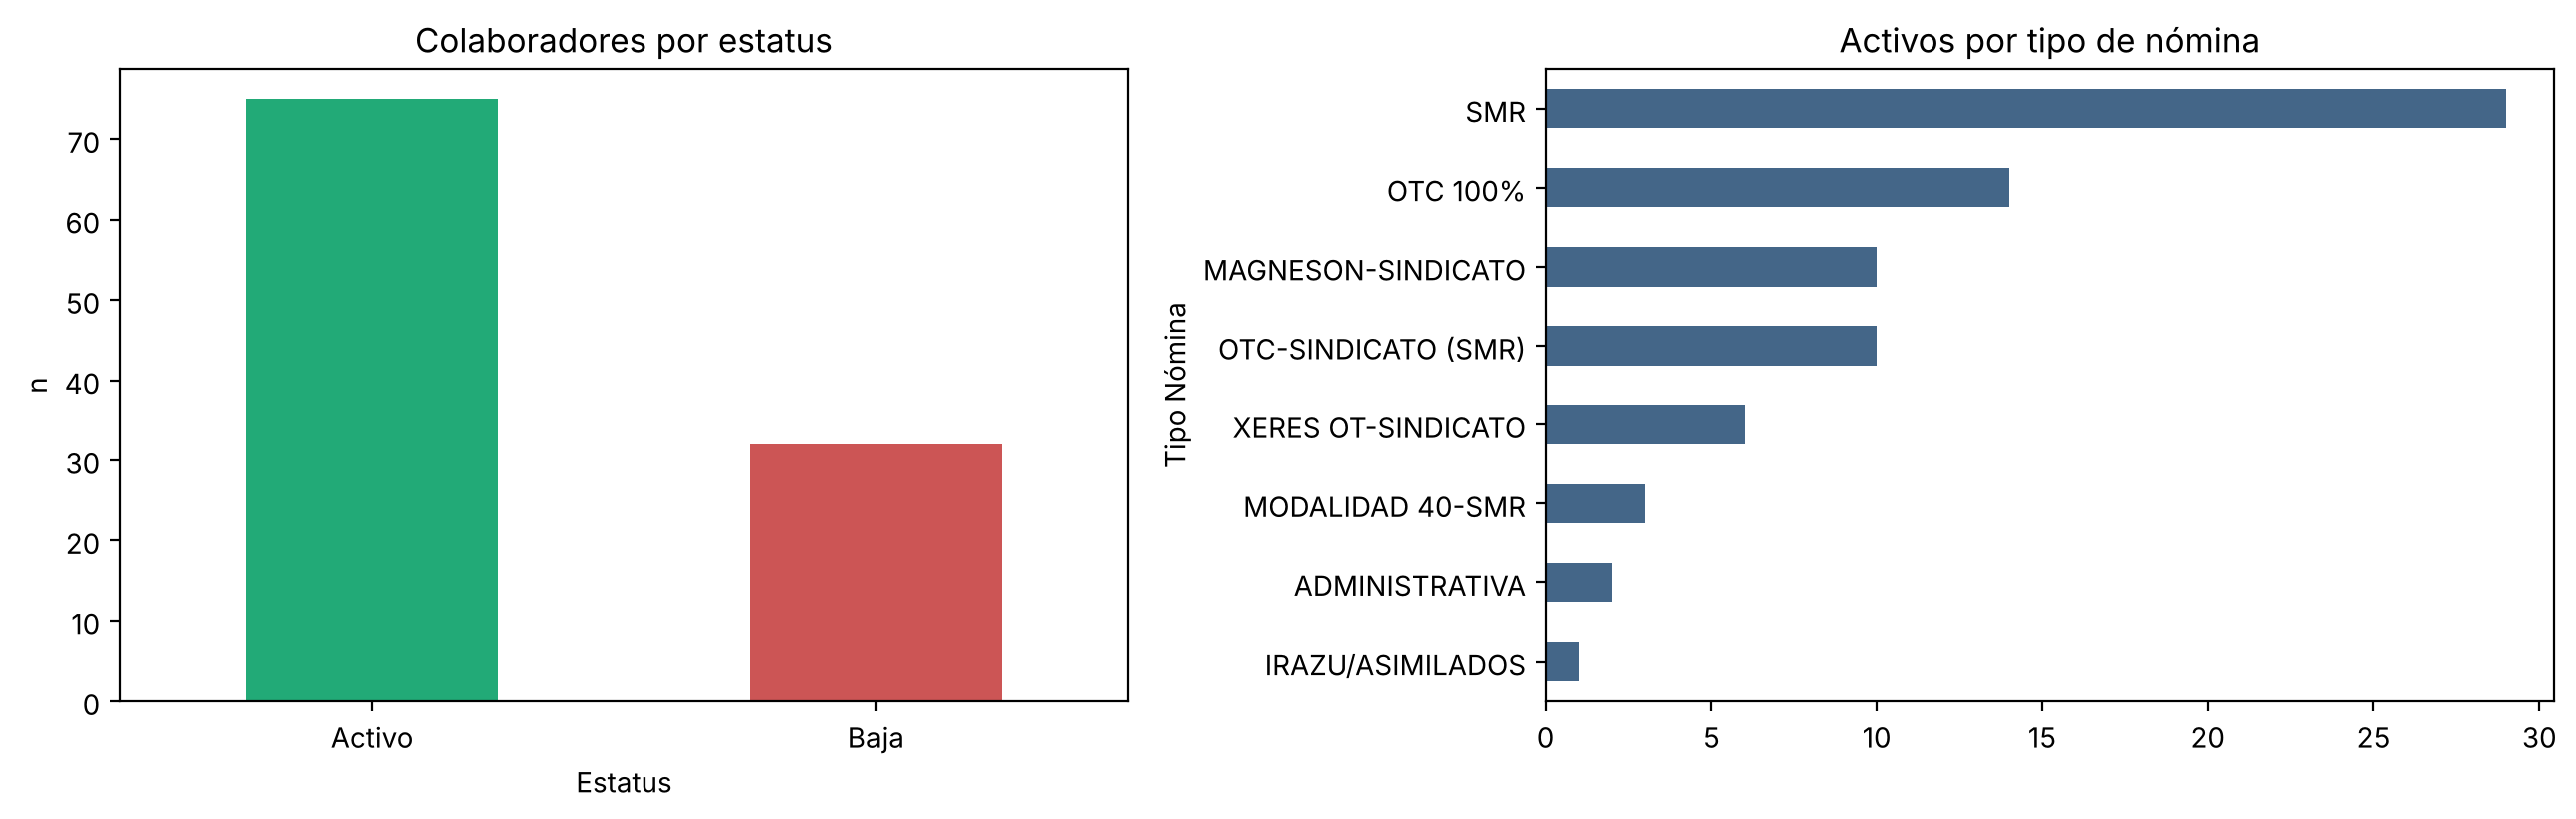

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
colab['Estatus'].value_counts().plot.bar(ax=ax[0], color=['#2a7','#c55'], rot=0); ax[0].set_title('Colaboradores por estatus'); ax[0].set_ylabel('n')
act['Tipo Nómina'].fillna('(sin dato)').value_counts().sort_values().plot.barh(ax=ax[1], color='#468'); ax[1].set_title('Activos por tipo de nómina')
plt.tight_layout(); plt.show()

**Lo que encontré en colaboradores.**
- Hay 75 activos (70.1%) y 32 bajas; 12 de las 14 bajas con fecha fueron en octubre de 2026.
- 29 activos tienen puesto PENDIENTE y 95 de 107 no tienen departamento.
- 18 bajas no tienen fecha de baja; OTC029 sigue activo con baja programada al 19 de noviembre.
- La edad promedio es 41.7 años y la antigüedad mediana 2.6 años.

## 2. Nómina y costo por colaborador

In [11]:
cols_s = ['Sueldo Neto IMSS','Sueldo Asimilados/Sindicato','Sueldo Complementos','Sueldo Neto Total','Comisión Nómina','Impuestos IMSS','Sueldo Total Integrado']
# Cuadre de fórmulas
colab['chk_neto']  = colab['Sueldo Neto IMSS'] + colab['Sueldo Asimilados/Sindicato'] + colab['Sueldo Complementos']
colab['chk_integ'] = colab['Sueldo Neto Total'] + colab['Comisión Nómina'] + colab['Impuestos IMSS']
print('Neto Total ≠ IMSS + Asimilados + Complementos:', int((abs(colab.chk_neto-colab['Sueldo Neto Total'])>1).sum()))
print('Total Integrado ≠ Neto Total + Comisión + Impuestos IMSS:', int((abs(colab.chk_integ-colab['Sueldo Total Integrado'])>1).sum()))

# Costo por hora = Sueldo Total Integrado / horas al mes
colab['costo_hora'] = (colab['Sueldo Total Integrado'] / HORAS_MES).round(2)
act = colab[colab.Estatus=='Activo'].copy()
print('\nSueldos de colaboradores ACTIVOS (MXN/mes)'); display(act[cols_s+['costo_hora']].describe().round(0))
print('Costo mensual total de la nómina activa (Total Integrado): $', f"{act['Sueldo Total Integrado'].sum():,.0f}")
print('\nCosto promedio por tipo de nómina (activos con sueldo > 0)')
display(act[act['Sueldo Total Integrado']>0].groupby('Tipo Nómina', dropna=False)['Sueldo Total Integrado'].agg(['count','mean','median','sum']).round(0).sort_values('sum', ascending=False))
print('Composición promedio del pago (activos con sueldo > 0)')
comp = act[act['Sueldo Total Integrado']>0][['Sueldo Neto IMSS','Sueldo Asimilados/Sindicato','Sueldo Complementos','Comisión Nómina','Impuestos IMSS']].mean().round(0); display(comp.to_frame('promedio MXN'))

Neto Total ≠ IMSS + Asimilados + Complementos: 0
Total Integrado ≠ Neto Total + Comisión + Impuestos IMSS: 0

Sueldos de colaboradores ACTIVOS (MXN/mes)


,Sueldo Neto IMSS,Sueldo Asimilados/Sindicato,Sueldo Complementos,Sueldo Neto Total,Comisión Nómina,Impuestos IMSS,Sueldo Total Integrado,costo_hora
count,75.0,75.0,75.0,75.0,75.0,75.0,75.0,75.0
mean,13369.0,28716.0,1597.0,43682.0,1740.0,6829.0,52252.0,327.0
std,15134.0,25638.0,5228.0,25274.0,1593.0,8750.0,28371.0,177.0
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,7147.0,1722.0,0.0,28000.0,0.0,3223.0,34078.0,213.0
50%,9198.0,29302.0,0.0,42631.0,1824.0,3236.0,51573.0,322.0
75%,9199.0,45106.0,0.0,54125.0,2947.0,5828.0,66237.0,414.0
max,66608.0,123029.0,29392.0,132227.0,5342.0,39442.0,135461.0,847.0


Costo mensual total de la nómina activa (Total Integrado): $ 3,918,864

Costo promedio por tipo de nómina (activos con sueldo > 0)


,count,mean,median,sum
Tipo Nómina,,,,
SMR,28,46776.0,45830.0,1309722.0
OTC 100%,13,63674.0,66961.0,827765.0
OTC-SINDICATO (SMR),10,63837.0,64666.0,638368.0
MAGNESON-SINDICATO,10,52975.0,52936.0,529747.0
XERES OT-SINDICATO,6,73107.0,59564.0,438643.0
MODALIDAD 40-SMR,3,58207.0,53000.0,174620.0


Composición promedio del pago (activos con sueldo > 0)


,promedio MXN
Sueldo Neto IMSS,14324.0
Sueldo Asimilados/Sindicato,30767.0
Sueldo Complementos,1711.0
Comisión Nómina,1864.0
Impuestos IMSS,7317.0


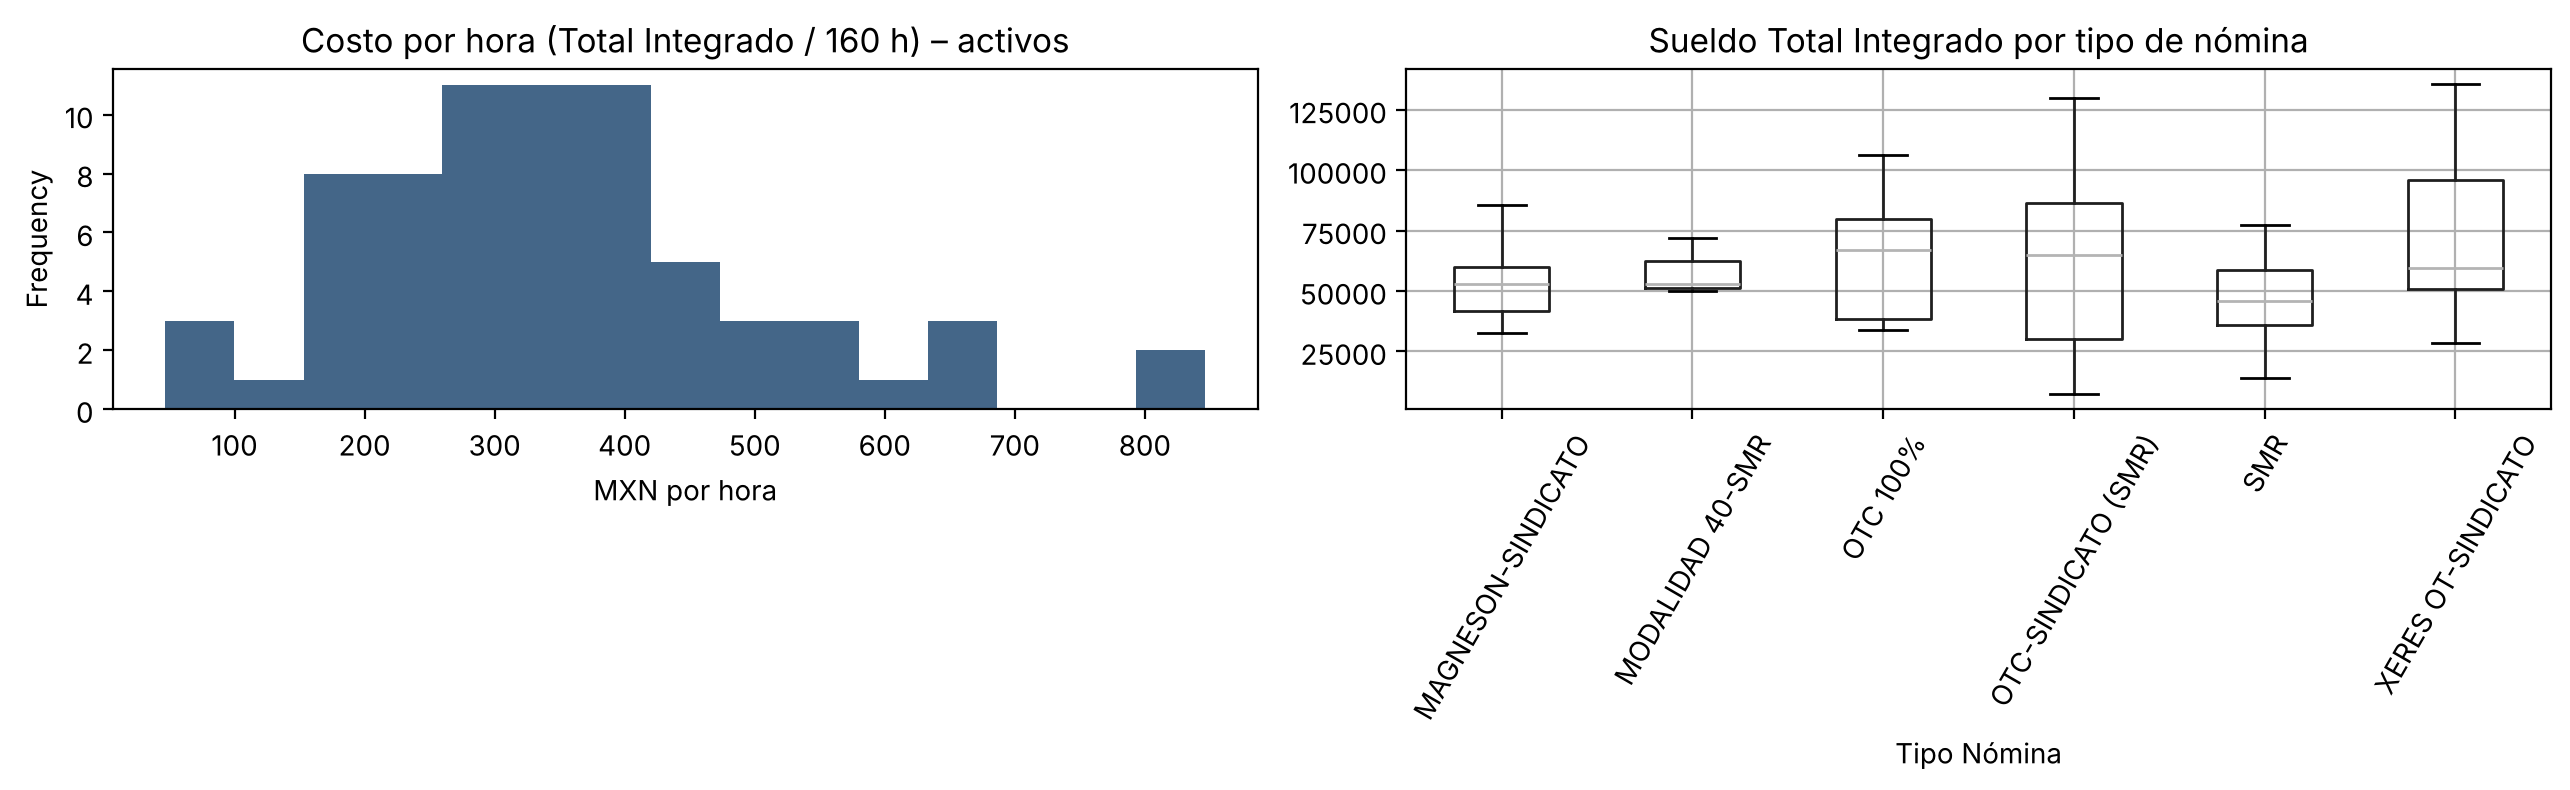

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
act[act['Sueldo Total Integrado']>0]['costo_hora'].plot.hist(bins=15, ax=ax[0], color='#468'); ax[0].set_title('Costo por hora (Total Integrado / 160 h) – activos'); ax[0].set_xlabel('MXN por hora')
act[act['Sueldo Total Integrado']>0].boxplot(column='Sueldo Total Integrado', by='Tipo Nómina', ax=ax[1], rot=60); ax[1].set_title('Sueldo Total Integrado por tipo de nómina'); plt.suptitle('')
plt.tight_layout(); plt.show()

In [13]:
# Consistencia entre Sueldos_Salarios_OTC y el catálogo de colaboradores
mm = sueldos.merge(colab[['ID','Estatus','Sueldo Neto Total','Sueldo Total Integrado','Puesto']], on='ID', how='left', suffixes=('','_cat'))
print('Filas en Sueldos:', len(sueldos), '| IDs que no existen en el catálogo:', int(mm.Estatus_cat.isna().sum()))
print('Diferencias de Sueldo Neto Total vs catálogo:', int((abs(mm['Sueldo Neto Total']-mm['Sueldo Neto Total_cat'])>0.01).sum()))
print('Activos del catálogo que no aparecen en Sueldos:', sorted(set(act.ID)-set(sueldos.ID)))
print('Activos con sueldo = 0:'); display(act[act['Sueldo Total Integrado']==0][['ID','Nombre Completo','Puesto','Tipo Nómina']])
print('Bajas con sueldo > 0 en el catálogo:', int((colab[colab.Estatus=='Baja']['Sueldo Total Integrado']>0).sum()))

Filas en Sueldos: 75 | IDs que no existen en el catálogo: 0
Diferencias de Sueldo Neto Total vs catálogo: 0
Activos del catálogo que no aparecen en Sueldos: []
Activos con sueldo = 0:


,ID,Nombre Completo,Puesto,Tipo Nómina
10,OTC013,ARMANDINA PEREZ GARCÍA,ADMINISTRACIÓN FINANZAS SENIOR,ADMINISTRATIVA
39,OTC043,JORGE PEREZ AMADOR,PENDIENTE,SMR
45,OTC049,JOSÉ ANDRÉS PEREZ GONZÁLEZ,ADMINISTRACIÓN FINANZAS GERENTE,OTC 100%
69,OTC073,MARIA DE PEREZ JUAREZ,PENDIENTE,IRAZU/ASIMILADOS
76,OTC080,NANCY ADRIANA PEREZ TOVIAS,ADMINISTRACIÓN FINANZAS GERENTE,ADMINISTRATIVA


Bajas con sueldo > 0 en el catálogo: 12


**Lo que encontré en nómina.**
- Las fórmulas de sueldo cuadran en el 100% de los registros; el costo por persona es confiable.
- La nómina activa cuesta $3,918,864 al mes; el costo promedio por hora es $349.9 (R10).
- 5 activos tienen sueldo 0 y 12 bajas conservan su sueldo.

## 3. Documentación del expediente (RH)

In [14]:
docs = [c for c in colab.columns if c.startswith(('Doc:','Aviso:','Formato:'))]
est_doc = pd.DataFrame({c: colab.loc[colab.Estatus=='Activo', c].value_counts() for c in docs}).T.fillna(0).astype(int)
est_doc['%_pendiente'] = (est_doc.get('Pendiente', 0) / 75 * 100).round(0)
est_doc.sort_values('%_pendiente', ascending=False)

,NO,NO APLICA,Pendiente,Planta,Por Proyecto,SI,%_pendiente
Aviso: Manutención,0,8,66,0,0,1,88.0
Aviso: Infonavit,0,5,65,0,0,5,87.0
Doc: Contrato,0,0,61,9,5,0,81.0
Doc: Foto,0,0,45,0,0,30,60.0
Doc: Const. Situación Fiscal,0,0,22,0,0,53,29.0
Doc: Comprobante Domicilio,0,0,21,0,0,54,28.0
Doc: INE,0,0,19,0,0,56,25.0
Doc: NSS,0,0,18,0,0,57,24.0
Doc: Banco,0,0,18,0,0,57,24.0
Doc: CURP,0,0,17,0,0,58,23.0


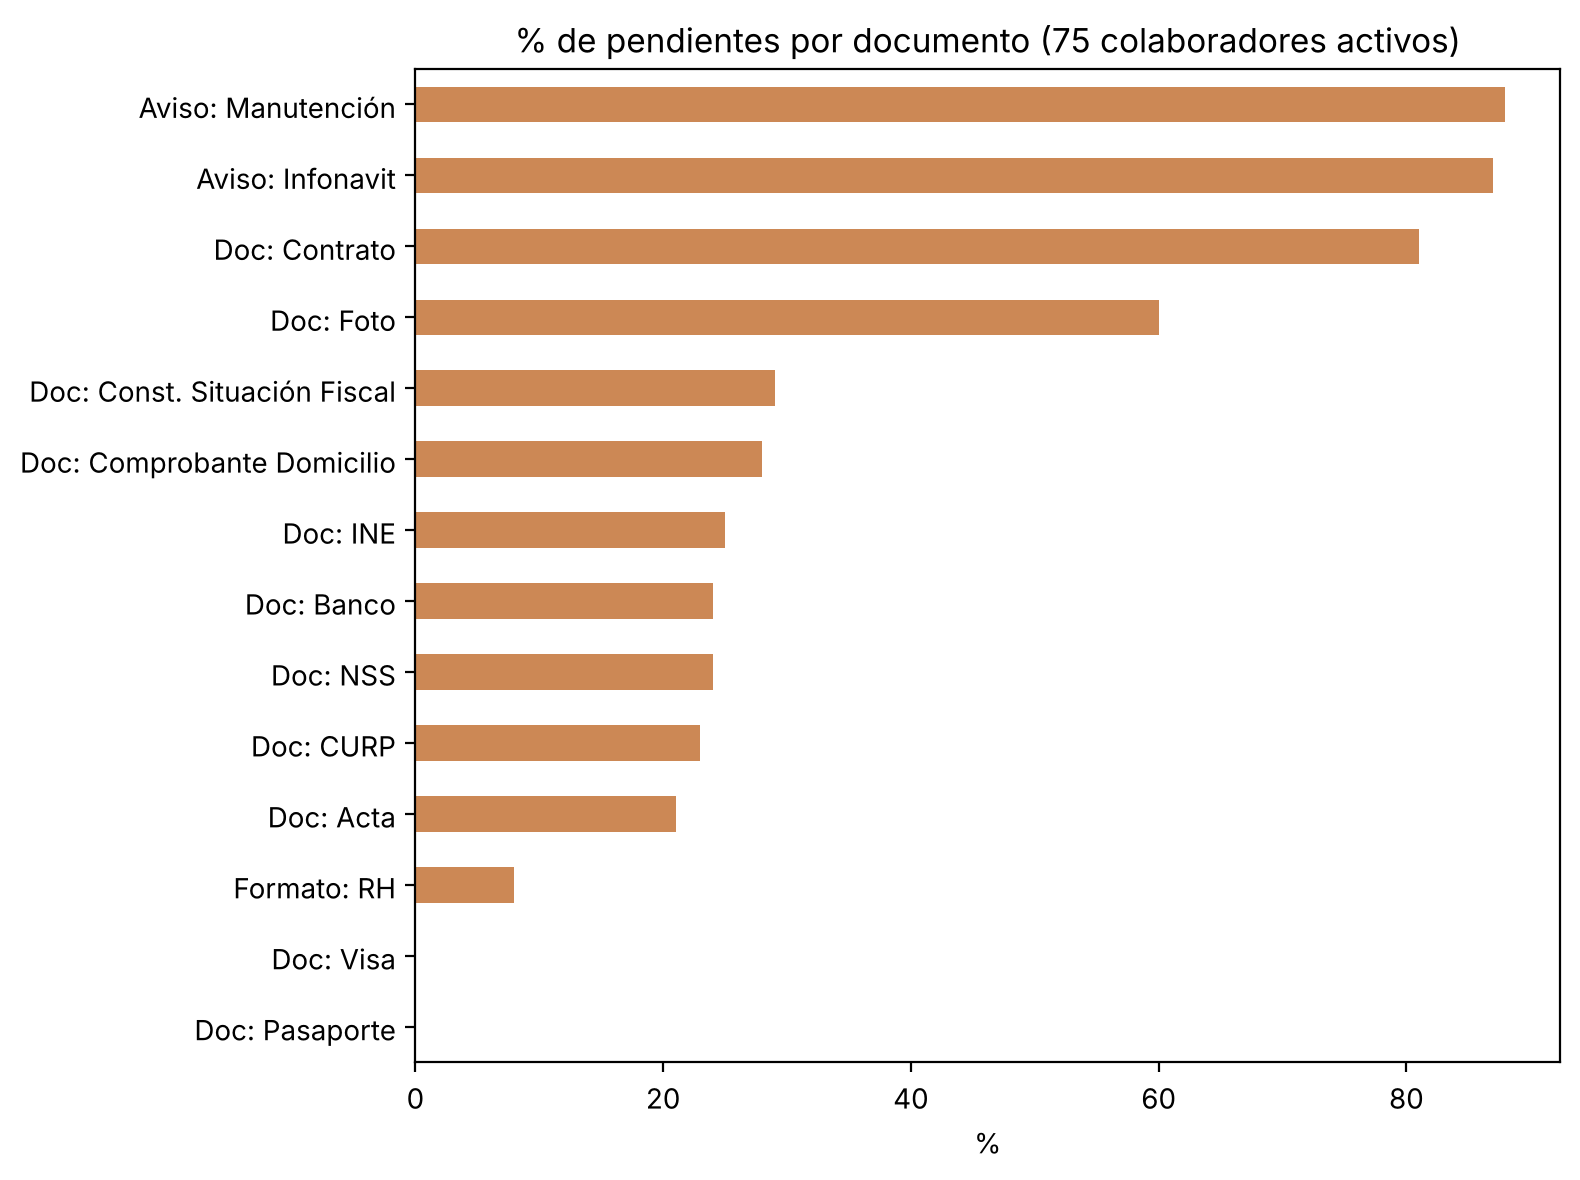

Expedientes básicos completos (7 de 7): 41 de 75


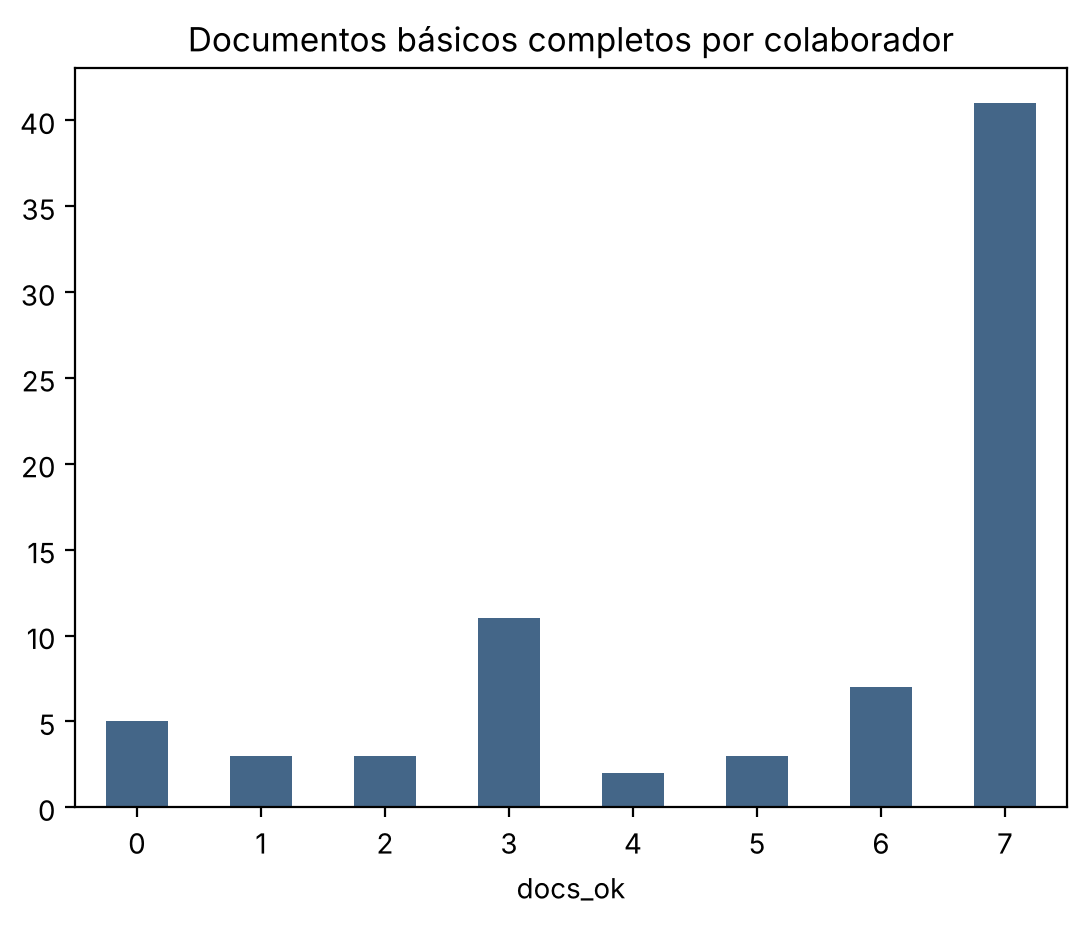

In [15]:
(est_doc['%_pendiente']).sort_values().plot.barh(figsize=(8,6), color='#c85'); plt.title('% de pendientes por documento (75 colaboradores activos)'); plt.xlabel('%'); plt.tight_layout(); plt.show()
act_docs = colab[colab.Estatus=='Activo'].copy()
core = ['Doc: Acta','Doc: INE','Doc: CURP','Doc: Const. Situación Fiscal','Doc: NSS','Doc: Comprobante Domicilio','Doc: Banco']
act_docs['docs_ok'] = (act_docs[core]=='SI').sum(axis=1)
print('Expedientes básicos completos (7 de 7):', int((act_docs.docs_ok==7).sum()), 'de', len(act_docs))
act_docs['docs_ok'].value_counts().sort_index().plot.bar(rot=0, color='#468'); plt.title('Documentos básicos completos por colaborador'); plt.show()

**Lo que encontré en el expediente.**
- Solo 41 de 75 activos tienen los 7 documentos básicos.
- El contrato está pendiente en 81% de los activos y la foto en 60%.

## 4. Asignaciones a clientes y proyectos

In [16]:
asig['ini'] = pd.to_datetime(asig['Fecha Inicio'], errors='coerce')
asig['fin'] = pd.to_datetime(asig['Fecha Fin'], errors='coerce')
asig['dias_para_fin'] = (asig['fin'] - FECHA_CORTE).dt.days
print('Valores de Fecha Fin que no son fecha:', asig.loc[asig.fin.isna(),'Fecha Fin'].unique())
print('Fechas de inicio = 1990-01-01 (marcador):', int((asig['Fecha Inicio']=='1990-01-01').sum()), 'de', len(asig))
print('Rol Asignado = PENDIENTE:', int((asig['Rol Asignado']=='PENDIENTE').sum()), '| Nómina/Rol Interno = PENDIENTE:', int((asig['Nómina/Rol Interno']=='PENDIENTE').sum()))
print('\nAsignaciones por cliente / proyecto'); display(asig.groupby(['Cliente','Proyecto']).size().to_frame('personas'))
print('Tipo de asignación'); display(asig['Tipo de Asignación'].value_counts().to_frame('n'))
dup = asig['ID Colaborador'].value_counts(); print('Colaboradores con más de una asignación:'); display(asig[asig['ID Colaborador'].isin(dup[dup>1].index)])
n_act = int((colab.Estatus=='Activo').sum()); n_asig = asig['ID Colaborador'].nunique()
print(f'Activos con alguna asignación: {n_asig} de {n_act} ({n_asig/n_act:.0%}). Sin asignación registrada: {n_act-n_asig}')
print('\nAsignaciones con fecha fin conocida y días restantes'); display(asig[asig.fin.notna()][['ID Colaborador','Nombre Colaborador','Cliente','Proyecto','Fecha Inicio','Fecha Fin','dias_para_fin']].sort_values('dias_para_fin'))

Valores de Fecha Fin que no son fecha: <StringArray>
['Indefinido']
Length: 1, dtype: str
Fechas de inicio = 1990-01-01 (marcador): 21 de 31
Rol Asignado = PENDIENTE: 29 | Nómina/Rol Interno = PENDIENTE: 14

Asignaciones por cliente / proyecto


personas
Cliente        Proyecto                       
Allegion       Migración eBs                 5
Grupo Daltile  Marazzi                       3
METALSA        Asignación indefinida        18
               Soporte AMS Manufacta         5

Tipo de asignación


,n
Tipo de Asignación,
Proyecto,16
Asignación,15


Colaboradores con más de una asignación:


,ID Colaborador,Nombre Colaborador,Nómina/Rol Interno,Estatus Colaborador,Cliente,Proyecto,Rol Asignado,Tipo de Asignación,Estatus Asignación,Fecha Inicio,Fecha Fin,ini,fin,dias_para_fin
22,OTC095,SOFÍA EMIRA PEREZ MORALES,GERENTE DE PROYECTOS Y OPERACIONES,Activo,Grupo Daltile,Marazzi,PENDIENTE,Proyecto,En Curso,2026-01-01,2027-01-01,2026-01-01,2027-01-01,45.0
23,OTC095,SOFÍA EMIRA PEREZ MORALES,GERENTE DE PROYECTOS Y OPERACIONES,Activo,METALSA,Asignación indefinida,PENDIENTE,Asignación,En Curso,1990-01-01,Indefinido,1990-01-01,NaT,NaN


Activos con alguna asignación: 30 de 75 (40%). Sin asignación registrada: 45

Asignaciones con fecha fin conocida y días restantes


,ID Colaborador,Nombre Colaborador,Cliente,Proyecto,Fecha Inicio,Fecha Fin,dias_para_fin
4,OTC014,CARLOS ADRIAN PEREZ VALDEZ,Grupo Daltile,Marazzi,2026-01-01,2027-01-01,45.0
9,OTC050,JUAN CARLOS PEREZ PRISCILIANO,Grupo Daltile,Marazzi,2026-01-01,2027-01-01,45.0
22,OTC095,SOFÍA EMIRA PEREZ MORALES,Grupo Daltile,Marazzi,2026-01-01,2027-01-01,45.0
27,OTC104,JAVIER ALEJANDRO PEREZ GARZA,Allegion,Migración eBs,2026-10-13,2027-07-01,226.0
28,OTC105,LUIS ALONSO PEREZ ALVAREZ,Allegion,Migración eBs,2026-10-13,2027-07-01,226.0
29,OTC106,MARIO PEREZ PADRON,Allegion,Migración eBs,2026-10-13,2027-07-01,226.0
30,OTC107,GIOVANNI DE PEREZ VARGAS,Allegion,Migración eBs,2026-10-13,2028-07-01,592.0


Sin asignación registrada: 45


,n
Puesto,
PENDIENTE,15
CONSULTOR TÉCNICO ORACLE EBS SENIOR,4
CONSULTOR FUNCIONAL ORACLE CLOUD Y EBS SENIOR,3
CONSULTOR FUNCIONAL ORACLE EBS SENIOR,3
ADMINISTRACIÓN FINANZAS SENIOR,2
CONSULTOR TÉCNICO ORACLE CLOUD SENIOR,2
CONSULTOR TÉCNICO RPA SENIOR,2
ADMINISTRACIÓN FINANZAS GERENTE,2
FAMILIAR COLABORADOR,2


,n
Tipo Nómina,
SMR,24
MAGNESON-SINDICATO,5
XERES OT-SINDICATO,4
OTC-SINDICATO (SMR),3
MODALIDAD 40-SMR,3
OTC 100%,3
ADMINISTRATIVA,2
IRAZU/ASIMILADOS,1


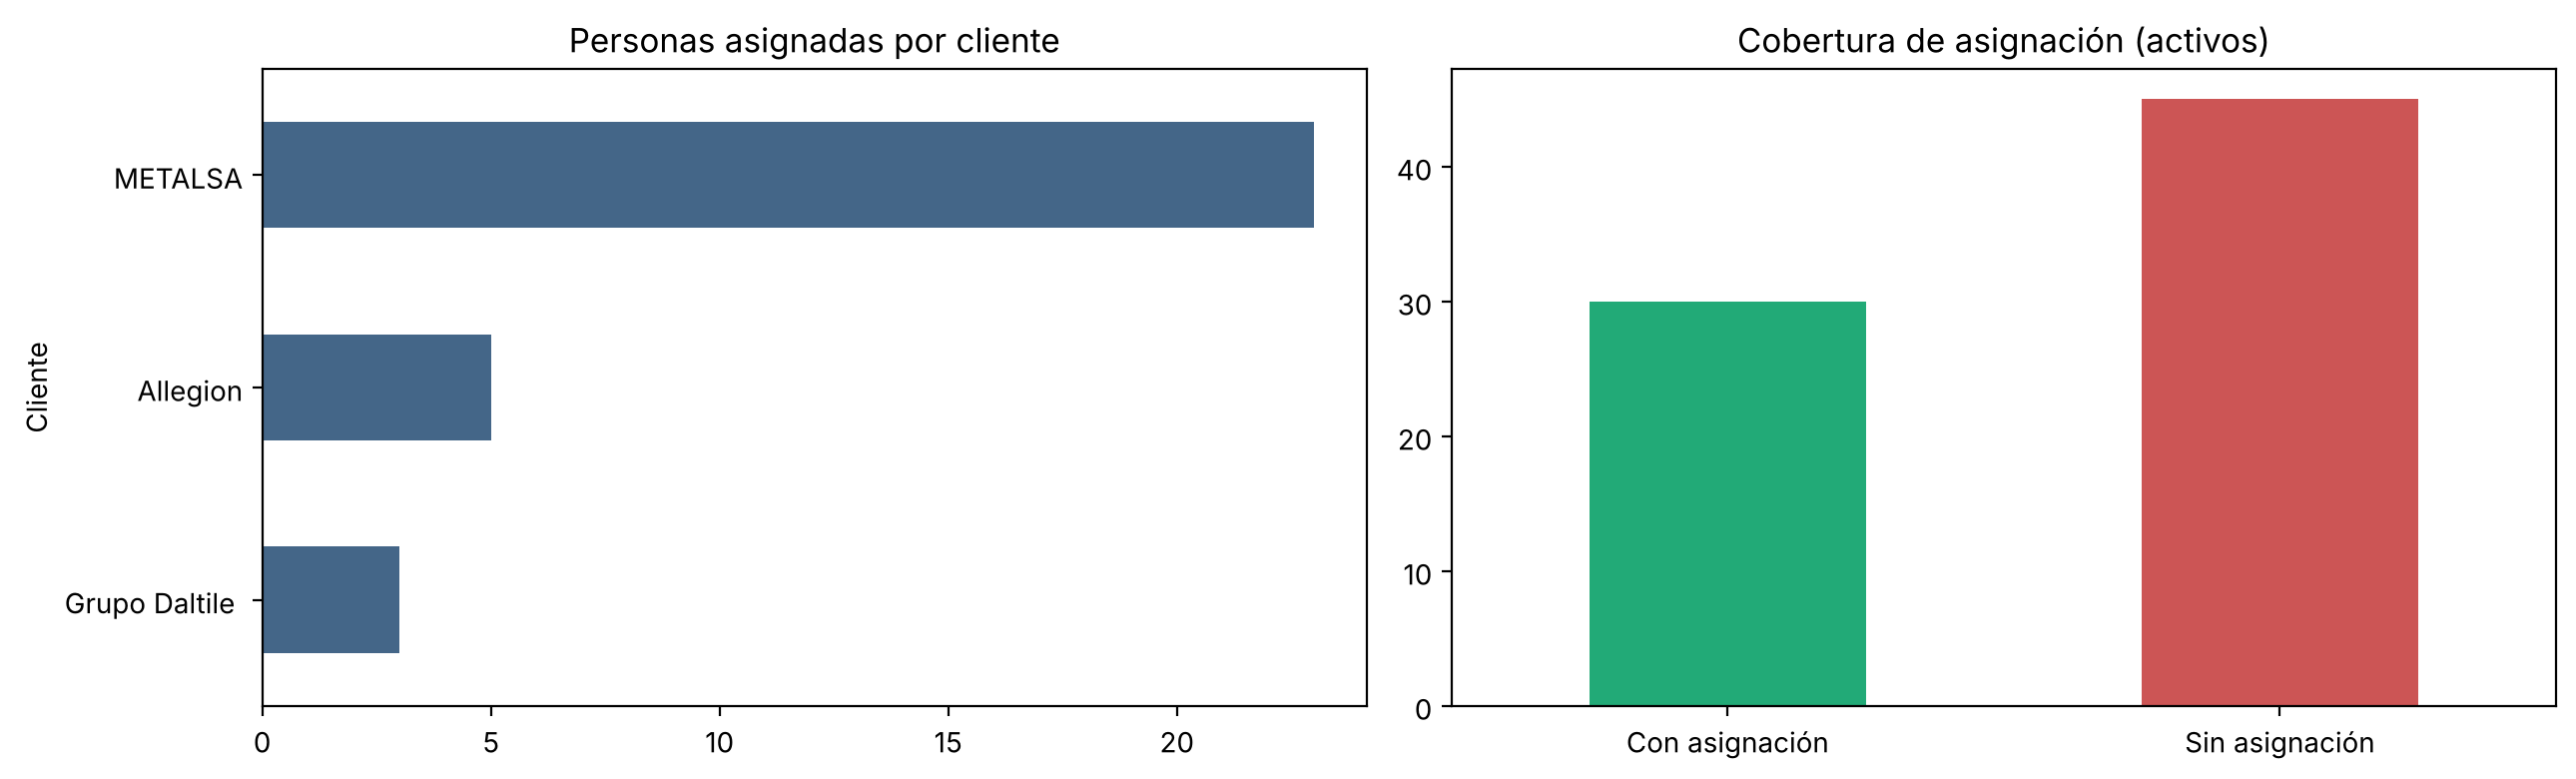

In [17]:
# Colaboradores sin asignación (banca potencial) por puesto
sin_asig = colab[(colab.Estatus=='Activo') & (~colab.ID.isin(asig['ID Colaborador']))]
print('Sin asignación registrada:', len(sin_asig)); display(sin_asig['Puesto'].value_counts().head(10).to_frame('n'))
display(sin_asig['Tipo Nómina'].value_counts(dropna=False).to_frame('n'))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
asig.groupby('Cliente').size().sort_values().plot.barh(ax=ax[0], color='#468'); ax[0].set_title('Personas asignadas por cliente')
pd.Series({'Con asignación': n_asig, 'Sin asignación': n_act-n_asig}).plot.bar(ax=ax[1], rot=0, color=['#2a7','#c55']); ax[1].set_title('Cobertura de asignación (activos)')
plt.tight_layout(); plt.show()

In [18]:
# Cruce Asignaciones vs Catálogo de Clientes/Proyectos (fechas y existencia del proyecto)
clientes['ini_p'] = pd.to_datetime(clientes['Fecha Inicio'], errors='coerce'); clientes['fin_p'] = pd.to_datetime(clientes['Fecha Fin'], errors='coerce')
cr = asig.merge(clientes[['Cliente','Proyecto','ini_p','fin_p','Estatus Proyecto','PM OTC']], on=['Cliente','Proyecto'], how='left')
print('Asignaciones cuyo proyecto no existe en el catálogo de clientes:', int(cr['Estatus Proyecto'].isna().sum()))
inc = cr[(cr.fin_p.notna()) & (cr.fin.notna()) & (cr.fin != cr.fin_p)].drop_duplicates(['Cliente','Proyecto','Fecha Fin'])
print('Proyectos cuya fecha fin difiere entre Asignaciones y Clientes:'); display(inc[['Cliente','Proyecto','Fecha Inicio','ini_p','Fecha Fin','fin_p','Estatus Proyecto']])
vencidos = clientes[(clientes.fin_p < FECHA_CORTE) & (clientes['Estatus Proyecto']=='En Curso')]
print('Proyectos "En Curso" con fecha fin ya vencida al corte:'); display(vencidos[['Cliente','Proyecto','Fecha Fin','Estatus Proyecto']])
proy_sin_personal = clientes.merge(asig[['Cliente','Proyecto']].drop_duplicates().assign(tiene=1), on=['Cliente','Proyecto'], how='left')
print('Proyectos del catálogo sin ninguna persona asignada:'); display(proy_sin_personal[proy_sin_personal.tiene.isna()][['Cliente','Proyecto','Estatus Proyecto']])

Asignaciones cuyo proyecto no existe en el catálogo de clientes: 0
Proyectos cuya fecha fin difiere entre Asignaciones y Clientes:


,Cliente,Proyecto,Fecha Inicio,ini_p,Fecha Fin,fin_p,Estatus Proyecto
4,Grupo Daltile,Marazzi,2026-01-01,2026-07-15,2027-01-01,2026-09-23,En Curso
27,Allegion,Migración eBs,2026-10-13,2026-10-13,2027-07-01,2028-10-30,En Curso
30,Allegion,Migración eBs,2026-10-13,2026-10-13,2028-07-01,2028-10-30,En Curso


Proyectos "En Curso" con fecha fin ya vencida al corte:


,Cliente,Proyecto,Fecha Fin,Estatus Proyecto
3,Grupo Daltile,Marazzi,2026-09-23,En Curso
9,Rent A Center (RAC Mèxico Operaciones),SHINE - Asiganci´ñon de recursos de apoyo,2026-10-30,En Curso


Proyectos del catálogo sin ninguna persona asignada:


,Cliente,Proyecto,Estatus Proyecto
0,METALSA,AMS Manufactura,En Curso
4,Grupo Daltile,Asignación EBS temporal (3 meses),Por Iniciar
5,Grupo Daltile,Asignación Funcional-Técnico (4 meses),Por Iniciar
7,CITI,Soporte Oracle Cloud,En Curso
8,Parker Servicios de México,Desarrollo de Indicadores,Por Iniciar
9,Rent A Center (RAC Mèxico Operaciones),SHINE - Asiganci´ñon de recursos de apoyo,En Curso
10,Fanosa,Soporte DBA,En Curso
11,Novocast,Hosting eBS,Por Iniciar


**Lo que encontré en asignaciones.**
- Solo 30 de 75 activos (40%) tienen asignación; 45 podrían estar en banca.
- 21 de 31 asignaciones empiezan el 01/01/1990 (relleno) y 29 tienen rol PENDIENTE.
- Marazzi terminó el 23/09/2026 pero sus 3 asignaciones siguen hasta el 01/01/2027.
- 8 de 12 proyectos no tienen a nadie asignado.

## 5. Clientes

In [19]:
display(clientes.drop(columns=['ini_p','fin_p']))
print('Clientes:', clientes['Cód Cliente'].nunique(), '| Proyectos:', len(clientes))
print('Proyectos por estatus'); display(clientes['Estatus Proyecto'].value_counts().to_frame('n'))
print('Clientes por industria'); display(clientes.drop_duplicates('Cód Cliente')['Industria'].str.strip().value_counts().to_frame('n'))
print('Campos vacíos en proyectos:'); display((clientes.isna().mean()*100).round(0).to_frame('%nulo').T)

,Cód Cliente,Cliente,Industria,RFC,Contacto Principal,Email Contacto,Estatus Cliente,Proyecto,Fecha Inicio,Fecha Fin,PM OTC,PM Cliente,Estatus Proyecto
0,C0001,METALSA,Automotriz,NaN,Hernán Macías,NaN,Activo,AMS Manufactura,NaN,NaN,NaN,Andrés Alvarado,En Curso
1,C0001,METALSA,Automotriz,NaN,Hernán Macías,NaN,Activo,Soporte AMS Manufacta,NaN,NaN,NaN,NaN,En Curso
2,C0001,METALSA,Automotriz,NaN,Hernán Macías,NaN,Activo,Asignación indefinida,NaN,NaN,NaN,NaN,Por Iniciar
3,C0002,Grupo Daltile,Manufactura,NaN,Luis Mora,luis.mora@daltile.com.mx,Activo,Marazzi,2026-07-15,2026-09-23,NaN,NaN,En Curso
4,C0002,Grupo Daltile,Manufactura,NaN,Luis Mora,luis.mora@daltile.com.mx,Activo,Asignación EBS temporal (3 meses),NaN,NaN,JUAN JOSÉ CORONADO BRAVO,NaN,Por Iniciar
5,C0002,Grupo Daltile,Manufactura,NaN,Luis Mora,luis.mora@daltile.com.mx,Activo,Asignación Funcional-Técnico (4 meses),NaN,NaN,JUAN JOSÉ CORONADO BRAVO,NaN,Por Iniciar
6,C0003,Allegion,Manufactura,NaN,Jose Luis Barrios,jose.barrios@allegion.com,Activo,Migración eBs,2026-10-13,2028-10-30,NaN,Hugo Cervantes,En Curso
7,C0004,CITI,Consultoría,NaN,Edna Rodriguez,edna.rodriguez@citi.com.mx,Activo,Soporte Oracle Cloud,2025-06-01,NaN,Juan José Coronado Bravo,Sayda Castillo,En Curso
8,C0005,Parker Servicios de México,Manufactura,PSM991202C2A,Martín Montañez,martin.montanez@parker.com,Activo,Desarrollo de Indicadores,NaN,NaN,NaN,NaN,Por Iniciar
9,C0006,Rent A Center (RAC Mèxico Operaciones),Rentas de equipo,RMO100429T23,Oziel Juárez,Oziel.Juarez@rentacenter.com,Activo,SHINE - Asiganci´ñon de recursos de apoyo,2026-06-30,2026-10-30,Juan José Coronado Bravo,Oziel Juárez,En Curso


Clientes: 8 | Proyectos: 12
Proyectos por estatus


,n
Estatus Proyecto,
En Curso,7
Por Iniciar,5


Clientes por industria


,n
Industria,
Manufactura,5
Automotriz,1
Consultoría,1
Rentas de equipo,1


Campos vacíos en proyectos:


,Cód Cliente,Cliente,Industria,RFC,Contacto Principal,Email Contacto,Estatus Cliente,Proyecto,Fecha Inicio,Fecha Fin,PM OTC,PM Cliente,Estatus Proyecto,ini_p,fin_p
%nulo,0.0,0.0,0.0,67.0,0.0,25.0,0.0,0.0,50.0,75.0,50.0,50.0,0.0,50.0,75.0


**Lo que encontré en clientes.**
- Son 8 clientes y 12 proyectos; 7 en curso y 5 por iniciar.
- La mitad de los proyectos no tiene PM de OTC ni fecha de inicio; 2 siguen En Curso con fecha vencida.
- Hay errores de captura como Manufacta, Asiganci´ñon y Méxcio.

## 6. Activos (equipo de cómputo)

In [20]:
activos['Marca_std'] = activos['Marca'].str.strip().str.upper()
print('Variantes de marca en origen:', activos['Marca'].nunique(), '→ estandarizadas:', activos['Marca_std'].nunique())
display(pd.DataFrame({'origen': activos['Marca'].value_counts(), }).T)
display(activos['Marca_std'].value_counts().to_frame('equipos'))
print('Inversión total (Catalogo_Activos):', f"{activos.Costo.sum():,.0f}", '| Inversion_Activos_OTC:', f"{inversion.Costo.sum():,.0f}", '| coinciden fila a fila:', bool((activos.Costo.values==inversion.Costo.values).all()))
print('Equipos con costo = 0:', int((activos.Costo==0).sum()), 'de', len(activos), f"({(activos.Costo==0).mean():.0%})")
con_costo = activos[activos.Costo>0]; print('Costo promedio de equipos con costo registrado:', round(con_costo.Costo.mean()), '| mediana:', con_costo.Costo.median())
print('Sin asignar:', int((activos['Colaborador Asignado']=='Sin Asignar').sum()))
print('Fecha Inicio = 1990-01-01 (marcador):', int((activos['Fecha Inicio']=='1990-01-01').sum()), '| Fecha Fin con valor "Activo":', int((activos['Fecha Fin']=='Activo').sum()))
est = colab.set_index('Nombre Completo')['Estatus']
activos['estatus_resp'] = activos['Colaborador Asignado'].map(est)
print('\nEquipos asignados a colaboradores en BAJA (por recuperar):'); display(activos[activos.estatus_resp=='Baja'][['Cód Activo','Marca_std','Modelo','Colaborador Asignado','Fecha Inicio','Fecha Fin']])
multi = activos[activos.estatus_resp=='Activo']['Colaborador Asignado'].value_counts(); print('Colaboradores activos con más de 1 equipo:'); display(multi[multi>1].to_frame('equipos'))
sin_equipo = colab[(colab.Estatus=='Activo') & (~colab['Nombre Completo'].isin(activos['Colaborador Asignado']))]
print('Colaboradores activos sin equipo asignado:', len(sin_equipo))

Variantes de marca en origen: 12 → estandarizadas: 5


Marca,DELL,HP,LENOVO,ACER,Lenovo,DELL,HP,Dell,LENOVO,ASUS,Dell,Acer
origen,54,23,17,8,5,4,3,3,2,2,1,1


,equipos
Marca_std,
DELL,62
HP,26
LENOVO,24
ACER,9
ASUS,2


Inversión total (Catalogo_Activos): 567,916 | Inversion_Activos_OTC: 567,916 | coinciden fila a fila: True
Equipos con costo = 0: 70 de 123 (57%)
Costo promedio de equipos con costo registrado: 10715 | mediana: 11233.9
Sin asignar: 32
Fecha Inicio = 1990-01-01 (marcador): 35 | Fecha Fin con valor "Activo": 81

Equipos asignados a colaboradores en BAJA (por recuperar):


,Cód Activo,Marca_std,Modelo,Colaborador Asignado,Fecha Inicio,Fecha Fin
4,A0005,DELL,Inspiron Business 3520,ALEJANDRO PEREZ MORQUECHO,2025-08-25,2026-10-27
9,A0010,LENOVO,ThinkBook 14 G2 ITL,CRISTOPHER CARLOS PEREZ FLORES,2024-02-13,Activo
15,A0016,HP,HP 240 G8 5U0S4LT,ARELI PEREZ LOMA,1990-01-01,2026-10-13
24,A0026,DELL,Inspiron Business 3520,JOSÉ ENRIQUE PEREZ SÁNCHEZ,2025-01-24,Activo
25,A0027,DELL,Inspiron Business 3520,JOSÉ ANTONIO PEREZ HERRERA,2025-10-30,2026-10-29
28,A0030,DELL,VOSTRO 3400,JUAN CARLOS PEREZ VAZQUEZ,2022-05-16,Activo
32,A0034,DELL,Inspiron 15 3520,JULIO IVAN PEREZ VILCHIS,1990-01-01,Activo
39,A0041,LENOVO,V14 ITL,MANUEL ENRIQUE PEREZ LINARES,2024-08-23,2026-11-03
45,A0047,DELL,Inspiron Business 3520,NADIA PAOLA PEREZ ROMERO,2026-07-06,Activo
56,A0059,DELL,VOSTRO 3400,SERGIO PEREZ LOPEZ,1990-01-01,Activo


Colaboradores activos con más de 1 equipo:


,equipos
Colaborador Asignado,
CLAUDIO FABIAN PEREZ ANGUIANO,3
ADRIANA PEREZ NAVARRETE,2
ALBERTO ANTONIO PEREZ CHEE,2
EDGAR RENÉ PEREZ LÓPEZ,2
FABIAN ALFREDO PEREZ URBINA,2
GABRIEL ISACC PEREZ GARCÍA,2
JORGE PEREZ AMADOR,2
JESÚS HUMBERTO PEREZ GUERRA,2
JUAN MARTÍN PEREZ SIFUENTES,2


Colaboradores activos sin equipo asignado: 18


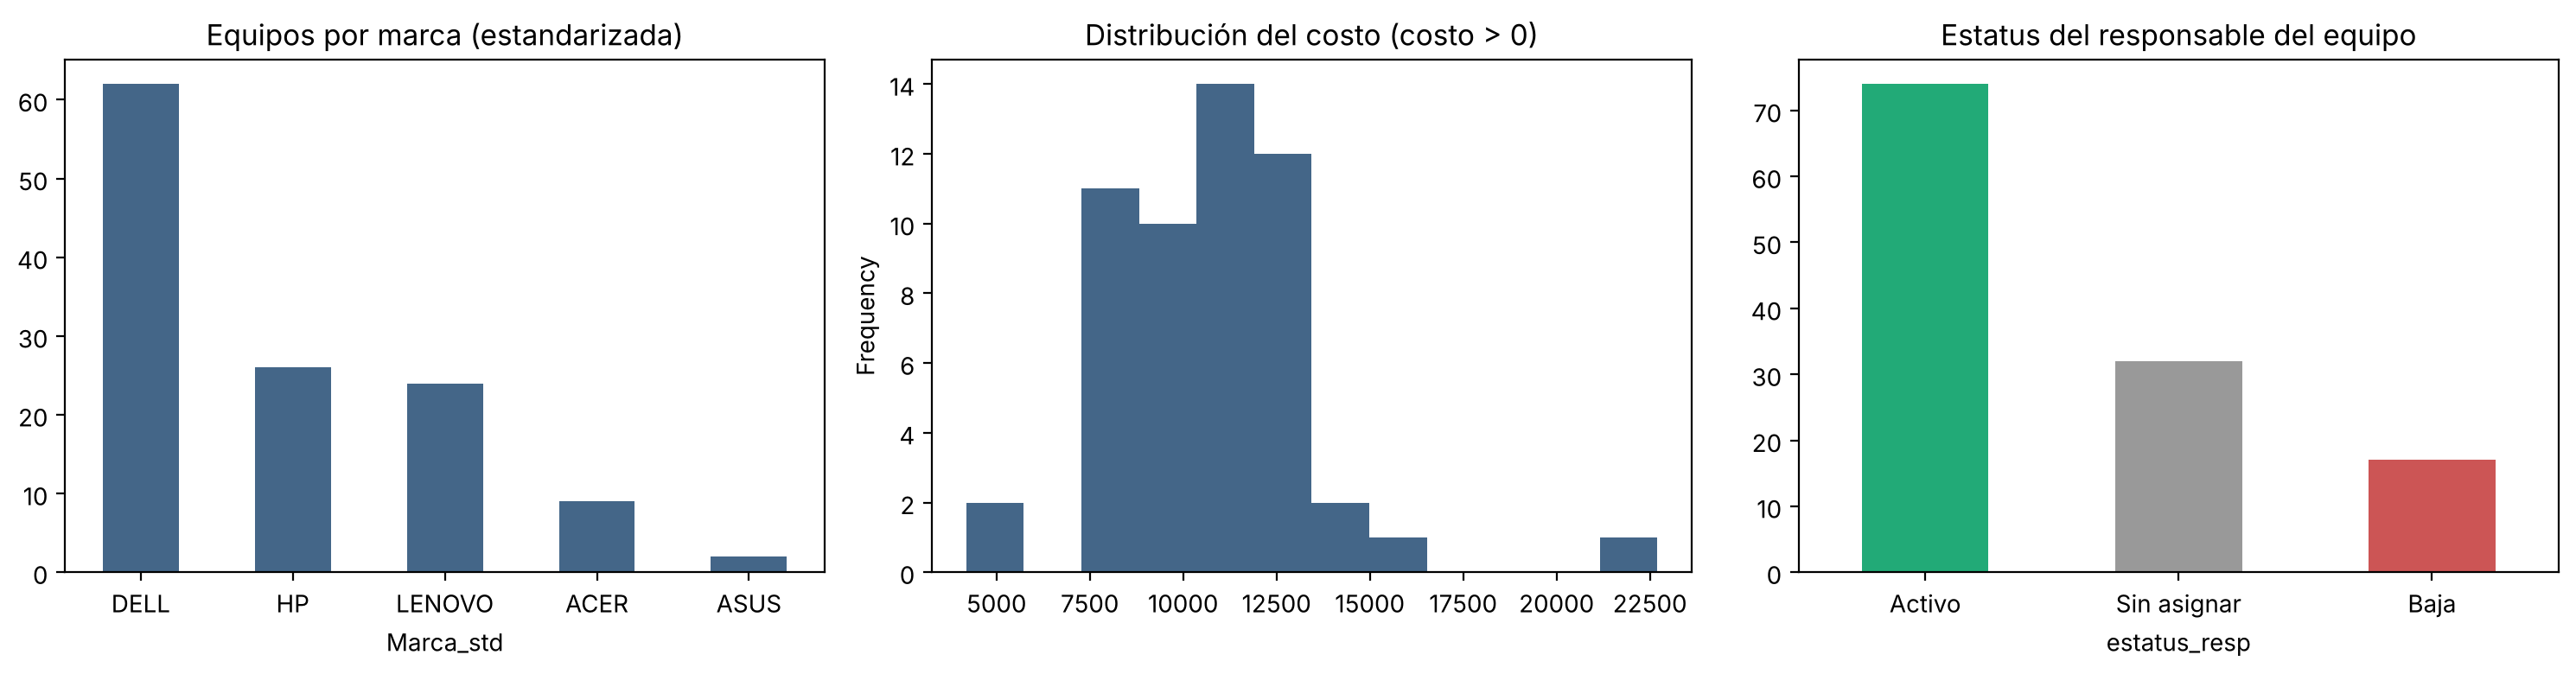

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
activos['Marca_std'].value_counts().plot.bar(ax=ax[0], rot=0, color='#468'); ax[0].set_title('Equipos por marca (estandarizada)')
con_costo['Costo'].plot.hist(bins=12, ax=ax[1], color='#468'); ax[1].set_title('Distribución del costo (costo > 0)')
activos['estatus_resp'].fillna('Sin asignar').value_counts().plot.bar(ax=ax[2], rot=0, color=['#2a7','#999','#c55']); ax[2].set_title('Estatus del responsable del equipo')
plt.tight_layout(); plt.show()

**Lo que encontré en activos.**
- Son 123 equipos de 5 marcas reales escritas de 12 formas.
- 70 equipos tienen costo 0; la inversión registrada de $567,916 está subestimada.
- 17 equipos están a nombre de bajas y 9 de ellos no tienen devolución.
- 16 activos tienen dos o más equipos y 18 no tienen ninguno.

## 7. Roles, departamentos y habilidades

In [22]:
print('Roles por nivel'); display(roles['Nivel'].value_counts().to_frame('roles'))
print('Roles sin departamento:'); display(roles[roles.Departamento.isna()][['Código','Nombre del Rol','Nivel']])
print('Puestos de colaboradores que no existen en el catálogo de roles:', sorted(set(colab.Puesto)-set(roles['Nombre del Rol'])))
print('\nDepartamentos: campos responsable / centroCostos vacíos →', int(deptos.responsable.isna().sum()), '/', int(deptos.centroCostos.isna().sum()), 'de', len(deptos))
display(deptos[['codigo','nombre','objetivo']])
print('Catálogo de habilidades por tecnología y tipo'); display(pd.crosstab(habs['tecnologia'], habs['tipo']))

Roles por nivel


,roles
Nivel,
Senior,16
Junior,15
Analista,14
Gerente,5
Director,3
Practicante,1
Jefe de Área,1


Roles sin departamento:


,Código,Nombre del Rol,Nivel
49,R0137,FAMILIAR COLABORADOR,Practicante
54,R0142,PENDIENTE,Jefe de Área


Puestos de colaboradores que no existen en el catálogo de roles: []

Departamentos: campos responsable / centroCostos vacíos → 6 / 6 de 6


,codigo,nombre,objetivo
0,D0001,Ventas,"Conseguir nuevos clientes, dar seguimient..."
1,D0002,Administración y Finanzas,Tener el control de los ingresos y egreso...
2,D0003,Recursos Humanos,"Reclutamiento y selección del personal, a..."
3,D0004,Operaciones y Soporte,"Control y seguimiento a los proyectos, ad..."
4,D0005,Dirección General,Administración general de OTC
5,D0006,Procesos y Mejora Continua,Administrar la documentación y automatiza...


Catálogo de habilidades por tecnología y tipo


tipo,HARD,SOFT
tecnologia,,
Certificaciones,0,1
Idiomas,0,1
Oracle Fusion Cloud,17,0
Oracle eBS,30,0
Otros,0,2
Plataformas Tecnológicas,20,0


In [23]:
col_h = [c for c in matriz.columns if ' - ' in c and c[0] in 'HS']
orden = {'Básico':1, 'Intermedio':2, 'Avanzado':3, 'Experto':4}
niv = matriz[col_h].replace(orden).apply(pd.to_numeric, errors='coerce')
tot = niv.size; print('Celdas persona×habilidad:', tot, '| con nivel:', int(niv.notna().sum().sum()), f"({niv.notna().sum().sum()/tot:.0%})", '| vacías:', int(niv.isna().sum().sum()))
print('Distribución de niveles'); display(pd.Series(matriz[col_h].values.ravel()).value_counts(dropna=False).rename_axis('nivel').to_frame('celdas'))
matriz['n_habs'] = niv.notna().sum(axis=1); matriz['nivel_prom'] = niv.mean(axis=1).round(2)
act_ids = set(colab.loc[colab.Estatus=='Activo','ID'])
print('Activos sin fila en la matriz:', len(act_ids-set(matriz['ID Colaborador'])), '| filas de la matriz con estatus Baja:', int((matriz.Estatus=='Baja').sum()))
print('\nHabilidades por persona'); display(matriz['n_habs'].describe().round(1).to_frame('n_habs').T)
print('Personas con ≤ 3 habilidades evaluadas (matriz poco confiable):'); display(matriz[matriz.n_habs<=3][['ID Colaborador','Nombre Completo','Estatus','n_habs']])
resumen = pd.DataFrame({'evaluados': niv.notna().sum(), 'expertos': (niv==4).sum(), 'avanzados+': (niv>=3).sum(), 'nivel_prom': niv.mean().round(2)}).sort_values('avanzados+', ascending=False)
print('Habilidades con más personas nivel Avanzado o Experto'); display(resumen.head(12))
print('Habilidades con 0 personas nivel Avanzado/Experto (huecos de cobertura):'); display(resumen[resumen['avanzados+']==0])

Celdas persona×habilidad: 3834 | con nivel: 1529 (40%) | vacías: 2305
Distribución de niveles


,celdas
nivel,
NaN,2305
Básico,686
Intermedio,369
Experto,244
Avanzado,230


Activos sin fila en la matriz: 28 | filas de la matriz con estatus Baja: 7

Habilidades por persona


,count,mean,std,min,25%,50%,75%,max
n_habs,54.0,28.3,20.3,1.0,14.0,22.5,38.5,69.0


Personas con ≤ 3 habilidades evaluadas (matriz poco confiable):


,ID Colaborador,Nombre Completo,Estatus,n_habs
10,OTC022,EDGAR RENÉ PEREZ LÓPEZ,Activo,1
13,OTC029,FRANCISCO PEREZ TOSCANO,Activo,1
36,OTC067,LUIS EUGENIO PEREZ RAMOS,Activo,3
53,OTC102,YOLANDA GABRIELA PEREZ CRUZ,Activo,2


Habilidades con más personas nivel Avanzado o Experto


,evaluados,expertos,avanzados+,nivel_prom
H0052 - PLSQL,44,16,26,2.68
H0068 - Oracle EBS,41,12,23,2.59
H0055 - REPORTS,32,13,18,2.69
H0054 - FORMS PERSONALIZADOS,27,8,17,2.67
H0010 - AP,34,8,16,2.41
H0017 - INV,33,13,16,2.48
H0015 - AR,32,8,15,2.47
H0039 - AR,27,7,15,2.70
H0053 - FORMS,30,8,15,2.43
H0037 - AP,27,6,15,2.59


Habilidades con 0 personas nivel Avanzado/Experto (huecos de cobertura):


,evaluados,expertos,avanzados+,nivel_prom
H0023 - OPM,12,0,0,1.25
H0028 - TALEO,9,0,0,1.22
H0062 - FUSE,10,0,0,1.20
S0004 - Empatia,0,0,0,NaN
S0005 - Manejo de Conflictos,0,0,0,NaN


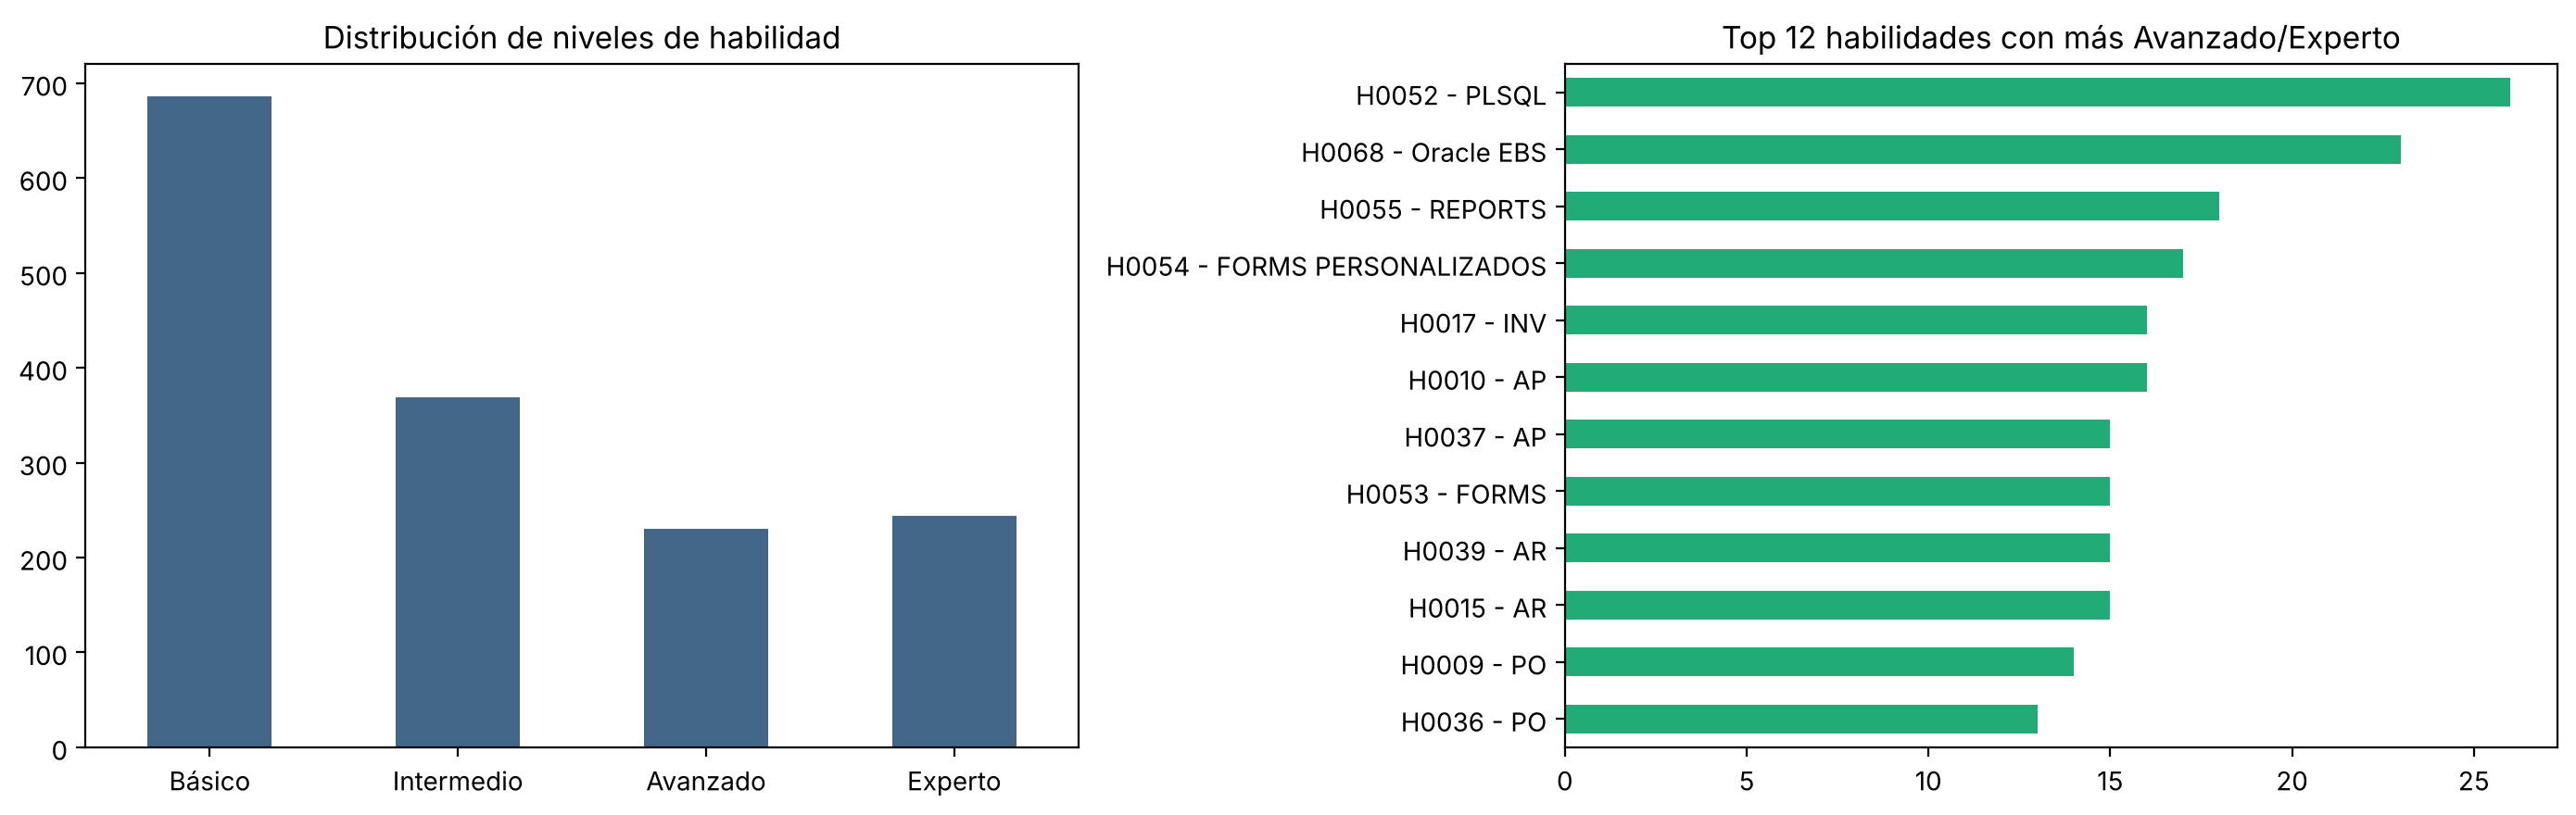

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
pd.Series(matriz[col_h].values.ravel()).value_counts().reindex(['Básico','Intermedio','Avanzado','Experto']).plot.bar(ax=ax[0], rot=0, color='#468'); ax[0].set_title('Distribución de niveles de habilidad')
resumen['avanzados+'].head(12).sort_values().plot.barh(ax=ax[1], color='#2a7'); ax[1].set_title('Top 12 habilidades con más Avanzado/Experto')
plt.tight_layout(); plt.show()

**Lo que encontré en catálogos y habilidades.**
- PENDIENTE está dado de alta como rol y 31 de 55 roles no los usa nadie.
- Ningún departamento tiene responsable ni centro de costos.
- Solo 40% de las celdas de la matriz tienen nivel y 28 activos no están evaluados.
- PLSQL es la habilidad más fuerte (26 personas Avanzado o más); OPM, TALEO y FUSE no tienen a nadie en ese nivel.

## 8. Bitácora de errores, faltantes e inconsistencias (modelo sugerido)

In [25]:
H = []
def add(tabla, campo, tipo, descripcion, n, total, sev, accion):
    H.append(dict(tabla=tabla, campo=campo, tipo=tipo, descripcion=descripcion, afectados=int(n), universo=int(total), pct=round(100*n/total,1) if total else None, severidad=sev, accion_sugerida=accion))

act = colab[colab.Estatus=='Activo']; baj = colab[colab.Estatus=='Baja']
# --- Colaboradores
add('Colaboradores','Puesto','Dato faltante','Puesto = PENDIENTE (todos los colaboradores)', (colab.Puesto=='PENDIENTE').sum(), len(colab), 'Alta','Asignar puesto del catálogo de roles')
add('Colaboradores','Puesto','Dato faltante','Puesto = PENDIENTE en colaboradores ACTIVOS', (act.Puesto=='PENDIENTE').sum(), len(act), 'Alta','Completar antes de calcular costo por rol')
add('Colaboradores','Departamento','Dato faltante','Departamento vacío', colab.Departamento.isna().sum(), len(colab), 'Alta','Derivar del rol (catálogo de roles)')
add('Colaboradores','Tipo Nómina','Dato faltante','Tipo de nómina vacío', colab['Tipo Nómina'].isna().sum(), len(colab), 'Media','Capturar o marcar como bajas sin nómina')
add('Colaboradores','Tipo Nómina','Inconsistencia','Categorías solapadas: SMR / OTC-SINDICATO (SMR) / MODALIDAD 40-SMR', colab['Tipo Nómina'].str.contains('SMR', na=False).sum(), len(colab), 'Media','Estandarizar a una sola clave de esquema')
add('Colaboradores','Fecha de Baja','Inconsistencia','Estatus Baja sin fecha de baja', ((colab.Estatus=='Baja') & colab['Fecha de Baja'].isna()).sum(), len(baj), 'Alta','Recuperar fecha de baja')
add('Colaboradores','Fecha de Baja','Inconsistencia','Estatus Activo con fecha de baja registrada (baja futura 19-nov-2026)', ((colab.Estatus=='Activo') & colab['Fecha de Baja'].notna()).sum(), len(act), 'Media','Marcar como baja programada')
add('Colaboradores','Sueldo Total Integrado','Inconsistencia','Activos con sueldo = 0', (act['Sueldo Total Integrado']==0).sum(), len(act), 'Alta','Confirmar si son administrativos fuera de nómina o falta captura')
add('Colaboradores','Sueldo Total Integrado','Inconsistencia','Bajas que conservan sueldo > 0', (baj['Sueldo Total Integrado']>0).sum(), len(baj), 'Media','Poner en 0 al dar de baja o conservar histórico en otra tabla')
add('Colaboradores','Fecha Nacimiento / Incorporación','Dato faltante','Sin fecha de nacimiento ni de incorporación', (colab['Fecha Nacimiento'].isna() | colab['Fecha Incorporación'].isna()).sum(), len(colab), 'Baja','Capturar (registro FAMILIAR COLABORADOR)')
add('Colaboradores','Fecha Nacimiento','Valor atípico','Edad mayor a 70 años (nacimiento 1946)', (colab.edad>70).sum(), len(colab), 'Baja','Validar captura')
add('Colaboradores','SGMM','Inconsistencia','Valores mezclados (PLAN SEGURO/PLAN SEGUROS, SI/NO, PENDIENTE, NO LO ENVIO…)', colab.SGMM.nunique(), colab.SGMM.notna().sum(), 'Media','Catálogo de aseguradoras + bandera de cobertura')
add('Colaboradores','Ciudad','Inconsistencia','Ciudad sin estandarizar (MTY/Monterrey, Jalisco/Guadalajara, país Colombia, Matriz Coporativa…)', colab.Ciudad.nunique(), len(colab), 'Baja','Catálogo ciudad-estado-país')
add('Colaboradores','Beneficiario / Parentesco','Dato faltante','Beneficiario = Pendiente', (colab.Beneficiario=='Pendiente').sum(), len(colab), 'Media','Levantar beneficiarios (seguro de vida)')
add('Colaboradores','Notas','Columna vacía','Notas 100% vacía', colab.Notas.isna().sum(), len(colab), 'Baja','Eliminar o poblar')
for c_ in ['RFC','CURP','NSS','Teléfono','Correo Electrónico','Domicilio']:
    add('Colaboradores', c_, 'Dato enmascarado','Un solo valor para todos los registros (dato anonimizado, no sirve como identificador)', len(colab)-1 if colab[c_].nunique()==1 else 0, len(colab), 'Info','Usar ID como llave')
for c_ in ['Doc: Acta','Doc: INE','Doc: CURP','Doc: Const. Situación Fiscal','Doc: NSS','Doc: Comprobante Domicilio','Doc: Banco','Doc: Foto','Doc: Contrato','Formato: RH']:
    add('Colaboradores', c_, 'Dato faltante','Documento pendiente (activos)', (act[c_]=='Pendiente').sum(), len(act), 'Media' if c_!='Doc: Contrato' else 'Alta','Seguimiento de RH')
# --- Sueldos
add('Sueldos','Departamento','Dato faltante','Departamento vacío', sueldos.Departamento.isna().sum(), len(sueldos), 'Alta','Derivar del rol')
add('Sueldos','Puesto/Rol','Dato faltante','Puesto = PENDIENTE', (sueldos['Puesto/Rol']=='PENDIENTE').sum(), len(sueldos), 'Alta','Completar')
# --- Asignaciones
add('Asignaciones','Fecha Inicio','Valor marcador','Fecha inicio = 1990-01-01 (marcador de fecha desconocida)', (asig['Fecha Inicio']=='1990-01-01').sum(), len(asig), 'Alta','Recuperar fecha real')
add('Asignaciones','Fecha Fin','Tipo mezclado','Fecha fin = texto "Indefinido" en lugar de fecha', asig.fin.isna().sum(), len(asig), 'Media','Dejar nulo + bandera "indefinida"')
add('Asignaciones','Rol Asignado','Dato faltante','Rol asignado = PENDIENTE', (asig['Rol Asignado']=='PENDIENTE').sum(), len(asig), 'Alta','Capturar rol por proyecto')
add('Asignaciones','Nómina/Rol Interno','Dato faltante','Rol interno = PENDIENTE', (asig['Nómina/Rol Interno']=='PENDIENTE').sum(), len(asig), 'Media','Sincronizar con catálogo de colaboradores')
add('Asignaciones','Proyecto','Inconsistencia','"Asignación indefinida" funciona como proyecto comodín', (asig.Proyecto=='Asignación indefinida').sum(), len(asig), 'Alta','Reemplazar por proyecto/cliente real')
add('Asignaciones','Cobertura','Dato faltante','Activos sin asignación registrada', len(sin_asig), len(act), 'Alta','Confirmar si están en banca o falta captura')
add('Asignaciones','Fechas vs Clientes','Inconsistencia','Proyecto con fecha fin distinta entre Asignaciones y Catálogo de Clientes', len(inc), clientes['Proyecto'].nunique(), 'Alta','Definir fuente única de fechas de proyecto')
add('Asignaciones','Estatus Proyecto','Inconsistencia','Proyecto En Curso con fecha fin vencida', len(vencidos), len(clientes), 'Alta','Cerrar o renovar proyecto')
# --- Clientes
add('Clientes','RFC','Dato faltante','RFC vacío', clientes.RFC.isna().sum(), len(clientes), 'Media','Capturar')
add('Clientes','PM OTC','Dato faltante','Proyecto sin PM de OTC', clientes['PM OTC'].isna().sum(), len(clientes), 'Alta','Asignar PM')
add('Clientes','Fechas del proyecto','Dato faltante','Proyecto sin fecha de inicio', clientes['Fecha Inicio'].isna().sum(), len(clientes), 'Alta','Capturar')
add('Clientes','Fecha Fin','Dato faltante','Proyecto sin fecha de fin', clientes['Fecha Fin'].isna().sum(), len(clientes), 'Media','Capturar o marcar recurrente')
add('Clientes','Proyecto','Error de captura','Nombres con errores ("Manufacta", "Asiganci´ñon")', clientes.Proyecto.str.contains('Manufacta|Asiganci', regex=True).sum(), len(clientes), 'Baja','Corregir texto')
add('Clientes','Proyecto','Cobertura','Proyectos sin ninguna persona asignada', int(proy_sin_personal.tiene.isna().sum()), len(clientes), 'Media','Validar si son proyectos activos')
# --- Activos
add('Activos','Marca','Inconsistencia','Variantes de escritura de la misma marca', activos.Marca.nunique()-activos.Marca_std.nunique(), activos.Marca.nunique(), 'Baja','TRIM + MAYÚSCULAS')
add('Activos','Costo','Dato faltante','Costo = 0', (activos.Costo==0).sum(), len(activos), 'Alta','Buscar factura/proveedor')
add('Activos','Fecha Inicio','Valor marcador','Fecha inicio = 1990-01-01 o vacía', ((activos['Fecha Inicio']=='1990-01-01') | activos['Fecha Inicio'].isna()).sum(), len(activos), 'Media','Capturar fecha de entrega')
add('Activos','Fecha Fin','Tipo mezclado','Fecha fin con texto "Activo"', (activos['Fecha Fin']=='Activo').sum(), len(activos), 'Media','Dejar nulo + bandera vigente')
add('Activos','Colaborador Asignado','Inconsistencia','Equipo asignado a un colaborador en BAJA', (activos.estatus_resp=='Baja').sum(), len(activos), 'Alta','Recuperar equipo / reasignar')
add('Activos','Serie / Modelo','Dato faltante','Serie = PENDIENTE o modelo vacío', ((activos.Serie.str.upper()=='PENDIENTE') | activos.Modelo.isna()).sum(), len(activos), 'Baja','Completar')
add('Activos','Colaborador Asignado','Cobertura','Activos sin equipo asignado', len(sin_equipo), len(act), 'Media','Validar si usan equipo propio')
# --- Roles / Deptos / Matriz
add('Roles','Departamento','Dato faltante','Roles sin departamento', roles.Departamento.isna().sum(), len(roles), 'Media','Asignar departamento')
add('Departamentos','responsable / centroCostos','Columna vacía','Sin responsable ni centro de costos', len(deptos), len(deptos), 'Alta','Definir para poder costear por área')
add('Matriz','Celdas persona×habilidad','Dato faltante','Celdas sin nivel (no se distingue "no sabe" de "no evaluado")', int(niv.isna().sum().sum()), niv.size, 'Alta','Agregar nivel "Sin conocimiento" y fecha de evaluación')
add('Matriz','ID Colaborador','Cobertura','Activos sin fila en la matriz de habilidades', len(act_ids-set(matriz['ID Colaborador'])), len(act_ids), 'Alta','Levantar matriz')
add('Matriz','Estatus','Inconsistencia','Filas de colaboradores en baja', (matriz.Estatus=='Baja').sum(), len(matriz), 'Baja','Conservar sólo con fecha de corte')
add('Matriz','Departamento','Dato faltante','Departamento vacío', matriz.Departamento.isna().sum(), len(matriz), 'Media','Derivar del rol')
hallazgos = pd.DataFrame(H); hallazgos.insert(0, 'id', ['E%02d' % i for i in range(1, len(hallazgos)+1)])
hallazgos.to_csv('/content/hallazgos_calidad.csv', index=False, encoding='utf-8-sig')
print('Hallazgos registrados:', len(hallazgos)); display(hallazgos['severidad'].value_counts().to_frame('n'))
hallazgos

Hallazgos registrados: 60


,n
severidad,
Media,25
Alta,21
Baja,8
Info,6


,id,tabla,campo,tipo,descripcion,afectados,universo,pct,severidad,accion_sugerida
0,E01,Colaboradores,Puesto,Dato faltante,Puesto = PENDIENTE (todos los colaboradores),48,107,44.9,Alta,Asignar puesto del catálogo de roles
1,E02,Colaboradores,Puesto,Dato faltante,Puesto = PENDIENTE en colaboradores ACTIVOS,29,75,38.7,Alta,Completar antes de calcular costo por rol
2,E03,Colaboradores,Departamento,Dato faltante,Departamento vacío,95,107,88.8,Alta,Derivar del rol (catálogo de roles)
3,E04,Colaboradores,Tipo Nómina,Dato faltante,Tipo de nómina vacío,6,107,5.6,Media,Capturar o marcar como bajas sin nómina
4,E05,Colaboradores,Tipo Nómina,Inconsistencia,Categorías solapadas: SMR / OTC-SINDICATO...,49,107,45.8,Media,Estandarizar a una sola clave de esquema
5,E06,Colaboradores,Fecha de Baja,Inconsistencia,Estatus Baja sin fecha de baja,18,32,56.2,Alta,Recuperar fecha de baja
6,E07,Colaboradores,Fecha de Baja,Inconsistencia,Estatus Activo con fecha de baja registra...,1,75,1.3,Media,Marcar como baja programada
7,E08,Colaboradores,Sueldo Total Integrado,Inconsistencia,Activos con sueldo = 0,5,75,6.7,Alta,Confirmar si son administrativos fuera de...
8,E09,Colaboradores,Sueldo Total Integrado,Inconsistencia,Bajas que conservan sueldo > 0,12,32,37.5,Media,Poner en 0 al dar de baja o conservar his...
9,E10,Colaboradores,Fecha Nacimiento / Incorporación,Dato faltante,Sin fecha de nacimiento ni de incorporación,1,107,0.9,Baja,Capturar (registro FAMILIAR COLABORADOR)


### 8b. Validaciones adicionales propias

In [26]:
# 8b. Validaciones adicionales propias (cruces del Excel y respaldo JSON del sistema)
import json
RUTA_JSON = '/content/otc_backup_2026-11-17.json'
J = json.load(open(RUTA_JSON)) if os.path.exists(RUTA_JSON) else None
if J is None:
    print('No se encontró el JSON; se omiten E61, E66, E67 y E68')

# E61 contraseñas en el respaldo (solo se cuentan, nunca se imprimen)
if J:
    add('Respaldo JSON', 'usuarios.pass', 'Seguridad', 'Cuentas de administrador con contraseña en texto plano',
        sum(1 for u in J['usuarios'] if u.get('pass')), len(J['usuarios']), 'Alta', 'Cifrar contraseñas; no publicar el respaldo')

# E62 equipos de bajas sin fecha de devolución
sin_dev = activos[(activos.estatus_resp == 'Baja') & (activos['Fecha Fin'] == 'Activo')]
add('Activos', 'Fecha Fin', 'Inconsistencia', 'Equipo a nombre de una baja y sin fecha de devolución',
    len(sin_dev), int((activos.estatus_resp == 'Baja').sum()), 'Alta', 'Recuperar equipo')

# E63 proyecto comodín Por Iniciar con personas En Curso
ai = clientes[clientes.Proyecto == 'Asignación indefinida']
n_ai = int((asig.Proyecto == 'Asignación indefinida').sum()) if (ai['Estatus Proyecto'] == 'Por Iniciar').any() else 0
add('Clientes vs Asignaciones', 'Estatus Proyecto', 'Inconsistencia', '"Asignación indefinida" está Por Iniciar pero tiene personas En Curso',
    n_ai, len(asig), 'Alta', 'Corregir estatus')

# E64 asignaciones fuera de las fechas de su proyecto
fuera = cr[(cr.ini < cr.ini_p) | (cr.fin > cr.fin_p)]
add('Asignaciones', 'Fecha Inicio / Fecha Fin', 'Inconsistencia', 'Asignación fuera de las fechas de su proyecto',
    len(fuera), len(asig), 'Alta', 'Alinear fechas')

# E65 PM de OTC que no existe como colaborador
nombres = set(colab['Nombre Completo'].str.upper().str.strip())
pm = clientes['PM OTC'].dropna()
add('Clientes', 'PM OTC', 'Inconsistencia', 'PM de OTC que no existe en el catálogo de colaboradores',
    int((~pm.str.upper().str.strip().isin(nombres)).sum()), len(pm), 'Media', 'Ligar PM por ID')

if J:
    av = pd.DataFrame(J['activos'])
    # E66 equipos que no funcionan y siguen Activo
    add('Activos (JSON)', 'notas', 'Inconsistencia', 'Equipo con nota NO FUNCIONA o Ya no sirve y estatus Activo',
        int(av.notas.str.contains('FUNCIONA|no sirve', case=False).sum()), len(av), 'Media', 'Estatus Baja o En reparación')
    # E67 equipo entregado antes de comprarse
    aa = pd.DataFrame([dict(codigo=a['codigo'], fcompra=a['fcompra'], **x) for a in J['activos'] for x in a['asignaciones']])
    aa['fc'] = pd.to_datetime(aa.fcompra.replace('', np.nan)); aa['fi'] = pd.to_datetime(aa.f_ini)
    add('Activos (JSON)', 'Fecha Inicio', 'Inconsistencia', 'Equipo entregado antes de su fecha de compra',
        int(((aa.fi < aa.fc) & (aa.fi.dt.year > 1990)).sum()), len(aa), 'Baja', 'Validar fechas')
    # E68 vacíos del sistema que el Excel convirtió en NO
    cj = pd.DataFrame(J['colaboradores'])
    add('Colaboradores', 'Doc: Pasaporte', 'Inconsistencia', 'Vacíos del sistema que el Excel convirtió en NO',
        int((cj.doc_pasaporte == '').sum()), len(cj), 'Baja', 'Dejar vacío')

# E69 certificado Oracle con escala de nivel
cert = [c for c in matriz.columns if 'CERTIFICADO' in c][0]
add('Matriz', cert, 'Inconsistencia', 'Certificado registrado con escala de nivel en lugar de SI o NO',
    int(matriz[cert].notna().sum()), len(matriz), 'Baja', 'Cambiar a bandera SI o NO')

hallazgos = pd.DataFrame(H); hallazgos.insert(0, 'id', ['E%02d' % i for i in range(1, len(hallazgos) + 1)])
hallazgos.to_csv('/content/hallazgos_calidad.csv', index=False, encoding='utf-8-sig')
print('Hallazgos totales:', len(hallazgos))
display(hallazgos['severidad'].value_counts().to_frame('n'))
hallazgos.iloc[60:]

Hallazgos totales: 69


,n
severidad,
Media,27
Alta,25
Baja,11
Info,6


,id,tabla,campo,tipo,descripcion,afectados,universo,pct,severidad,accion_sugerida
60,E61,Respaldo JSON,usuarios.pass,Seguridad,Cuentas de administrador con contraseña e...,6,6,100.0,Alta,Cifrar contraseñas; no publicar el respaldo
61,E62,Activos,Fecha Fin,Inconsistencia,Equipo a nombre de una baja y sin fecha d...,9,17,52.9,Alta,Recuperar equipo
62,E63,Clientes vs Asignaciones,Estatus Proyecto,Inconsistencia,"""Asignación indefinida"" está Por Iniciar ...",18,31,58.1,Alta,Corregir estatus
63,E64,Asignaciones,Fecha Inicio / Fecha Fin,Inconsistencia,Asignación fuera de las fechas de su proy...,3,31,9.7,Alta,Alinear fechas
64,E65,Clientes,PM OTC,Inconsistencia,PM de OTC que no existe en el catálogo de...,6,6,100.0,Media,Ligar PM por ID
65,E66,Activos (JSON),notas,Inconsistencia,Equipo con nota NO FUNCIONA o Ya no sirve...,5,123,4.1,Media,Estatus Baja o En reparación
66,E67,Activos (JSON),Fecha Inicio,Inconsistencia,Equipo entregado antes de su fecha de compra,3,91,3.3,Baja,Validar fechas
67,E68,Colaboradores,Doc: Pasaporte,Inconsistencia,Vacíos del sistema que el Excel convirtió...,16,107,15.0,Baja,Dejar vacío
68,E69,Matriz,S0002 - CERTIFICADO ORACLE,Inconsistencia,Certificado registrado con escala de nive...,12,54,22.2,Baja,Cambiar a bandera SI o NO


## Respuesta. Errores, faltantes e inconsistencias

Son 69 hallazgos (60 del cuaderno del equipo y 9 míos en la sección 8b) y se exportan a hallazgos_calidad.csv.

**Modelo sugerido.** Cada hallazgo es un registro con id, tabla, campo, tipo, descripción, afectados, universo, porcentaje, severidad y acción sugerida; así se puede filtrar, priorizar y dar seguimiento.

Los más graves son el rol PENDIENTE en 29 de 31 asignaciones, las fechas de relleno 01/01/1990, los 45 activos sin asignación, los 70 equipos con costo 0, los 17 equipos a nombre de bajas y las contraseñas en texto plano del respaldo.

## Respuesta. Reglas de negocio

| ID | Regla |
| --- | --- |
| R01 | El ID es la llave del colaborador; nunca el nombre |
| R02 | Activo es quien tiene estatus Activo y no tiene baja antes del corte |
| R03 | El costo mensual de una persona es su Sueldo Total Integrado; un sueldo 0 es dato faltante, no costo cero |
| R04 | Un consultor puede estar en varios proyectos, pero su dedicación total no pasa de 100% |
| R05 | Un gerente o PM puede llevar varios proyectos y debe existir como colaborador |
| R06 | Si no hay porcentaje de dedicación, el costo se reparte en partes iguales; con dos asignaciones es 50/50 |
| R07 | 01/01/1990, Indefinido y Activo en una fecha significan fecha desconocida; se dejan vacías |
| R08 | Una asignación debe estar dentro de las fechas de su proyecto; PENDIENTE equivale a vacío |
| R09 | Un equipo tiene un solo responsable; al dar de baja a alguien se registra la devolución |
| R10 | Un mes laboral tiene 160 horas; costo por hora = Sueldo Total Integrado / 160 |
| R11 | Los textos se guardan sin espacios sobrantes y en mayúsculas; los datos sensibles quedan fuera del análisis |

## 9. Métricas derivadas (primer cálculo)

In [27]:
m = {}
act = colab[colab.Estatus=='Activo']
m['Headcount activo'] = len(act)
m['Bajas 2026 (con fecha)'] = int(baj['Fecha de Baja'].notna().sum())
m['Tasa de baja sobre total histórico'] = f"{len(baj)/len(colab):.1%}"
m['Costo mensual nómina activa (Total Integrado)'] = f"${act['Sueldo Total Integrado'].sum():,.0f}"
m['Costo promedio por hora (activos con sueldo)'] = f"${act[act['Sueldo Total Integrado']>0]['costo_hora'].mean():,.1f}"
m['Cobertura de asignación'] = f"{n_asig/n_act:.0%}"
m['Equipos registrados / inversión'] = f"{len(activos)} / ${activos.Costo.sum():,.0f}"
m['Equipos en manos de bajas'] = int((activos.estatus_resp=='Baja').sum())
m['Habilidades evaluadas (celdas)'] = f"{niv.notna().sum().sum()/niv.size:.0%}"
pd.Series(m).to_frame('valor')

,valor
Headcount activo,75
Bajas 2026 (con fecha),14
Tasa de baja sobre total histórico,29.9%
Costo mensual nómina activa (Total Integrado),"$3,918,864"
Costo promedio por hora (activos con sueldo),$349.9
Cobertura de asignación,40%
Equipos registrados / inversión,"123 / $567,916"
Equipos en manos de bajas,17
Habilidades evaluadas (celdas),40%


In [28]:
# Costo por hora de cada persona asignada a un proyecto y costo mensual por cliente (si todo su tiempo es al cliente)
cp = asig.merge(colab[['ID','Sueldo Total Integrado','costo_hora']], left_on='ID Colaborador', right_on='ID', how='left')
cp['n_asig'] = cp.groupby('ID Colaborador')['ID Colaborador'].transform('count')
cp['costo_mensual_asignado'] = cp['Sueldo Total Integrado'] / cp['n_asig']   # regla R6: si hay 2 asignaciones se reparte 50/50
print('Costo mensual de la plantilla asignada por cliente/proyecto (MXN)')
display(cp.groupby(['Cliente','Proyecto']).agg(personas=('ID Colaborador','nunique'), costo_mensual=('costo_mensual_asignado','sum'), costo_hora_prom=('costo_hora','mean')).round(0))

Costo mensual de la plantilla asignada por cliente/proyecto (MXN)


personas  costo_mensual  costo_hora_prom
Cliente        Proyecto                                                       
Allegion       Migración eBs                 5       164929.0            206.0
Grupo Daltile  Marazzi                       3       172382.0            464.0
METALSA        Asignación indefinida        18      1268864.0            458.0
               Soporte AMS Manufacta         5       318535.0            398.0

## Respuesta. Preguntas detonadoras

Se definen pero todavía no se responden.

| ID | Pregunta |
| --- | --- |
| P1 | ¿Qué porcentaje de consultores activos está asignado y cuántos están en banca? |
| P2 | ¿Qué consultores terminan su asignación en los próximos 30, 60 y 90 días? |
| P3 | ¿Qué proyectos activos no tienen personal y qué perfil necesitan? |
| P4 | ¿Cuál es el costo por hora de cada consultor? |
| P5 | ¿Cuánto cuesta al mes cada proyecto y cada cliente? |
| P6 | ¿Cuánto cuesta al mes la banca? |
| P7 | ¿Qué habilidades tienen menos de 2 personas con nivel Avanzado o Experto? |
| P8 | ¿Qué consultores en banca tienen las habilidades que piden los proyectos sin personal? |
| P9 | ¿Cuál es la rotación mensual y en qué puestos se concentra? |
| P10 | ¿Cuántos equipos siguen en manos de bajas y cuánto valen? |

## Respuesta. Métricas

| Métrica | Existe o nueva | Cálculo | Pregunta |
| --- | --- | --- | --- |
| Sueldo Total Integrado | Existe | Neto + comisión + impuestos IMSS | P4, P5, P6 |
| Costo del activo | Existe | Dato de origen; 0 = desconocido | P10 |
| Nivel de habilidad | Existe | Básico, Intermedio, Avanzado o Experto | P7, P8 |
| Headcount activo | Nueva | Colaboradores activos al corte | P1, P9 |
| Costo por hora | Nueva | Sueldo Total Integrado / 160 | P4 |
| Costo mensual asignado | Nueva | Sueldo Total Integrado / número de asignaciones | P5 |
| Días para fin de asignación | Nueva | Fecha fin − fecha de corte | P2 |
| Personas en banca | Nueva | Activos sin asignación vigente | P1, P6 |
| Costo de banca | Nueva | Suma del costo de la banca | P6 |
| Bajas por mes | Nueva | Conteo de fechas de baja por mes | P9 |
| Personas Avanzado o más | Nueva | Conteo de nivel 3 o 4 por habilidad | P7, P8 |
| Valor de equipos en bajas | Nueva | Suma del costo de esos equipos | P10 |

## Respuesta. Indicadores

Las metas son sugeridas; se validan con OTC.

| Indicador | Fórmula | Meta sugerida | Pregunta |
| --- | --- | --- | --- |
| Tasa de utilización | Activos asignados / activos × 100 | 85% o más | P1 |
| Asignaciones por vencer | Asignaciones que terminan en 30, 60 y 90 días | Todas con plan de reasignación | P2 |
| Proyectos sin cobertura | Proyectos activos sin personal / proyectos activos × 100 | 0% | P3 |
| Costo por proyecto | Suma del costo mensual asignado | Dentro del presupuesto | P5 |
| Peso de la banca | Costo de banca / costo de nómina × 100 | 10% o menos | P6 |
| Cobertura de habilidad | Personas Avanzado o más por habilidad | 2 o más | P7 |
| Rotación mensual | Bajas del mes / headcount × 100 | Menos de 2% | P9 |
| Equipos por recuperar | Equipos en manos de bajas | 0 | P10 |

## Respuesta. Atributos adicionales

| Atributo | Tabla | Para qué sirve | Pregunta |
| --- | --- | --- | --- |
| Porcentaje de dedicación | Asignaciones | Repartir el costo real de cada persona | P5 |
| Facturable (SI o NO) | Asignaciones | Separar trabajo cobrado del interno | P1, P6 |
| Tarifa de venta por hora | Proyectos | Calcular margen por proyecto | P5 |
| Perfil requerido | Proyectos | Cruzar vacantes con la banca | P3, P8 |
| ID del responsable y fecha de devolución | Activos | Ligar equipos por ID y saber qué se recuperó | P10 |
| Motivo de baja | Colaboradores | Explicar la rotación | P9 |
| Fecha de evaluación | Matriz | Saber si el nivel sigue vigente | P7 |

In [29]:
# Exporta evidencia
colab.drop(columns=['chk_neto','chk_integ']).to_csv('/content/colaboradores_limpios_parcial.csv', index=False, encoding='utf-8-sig')
print('Archivos generados:', [f for f in os.listdir('/content') if f.endswith('.csv')])

Archivos generados: ['colaboradores_limpios_parcial.csv', 'hallazgos_calidad.csv']


## Evidencias

Este cuaderno importa los 10 archivos (sección 0), los perfila columna por columna y los explora tabla por tabla (secciones 1 a 7). Al final exporta hallazgos_calidad.csv y colaboradores_limpios_parcial.csv como evidencia del trabajo.